# Detekcja Phishingu - SVM (Support Vector Machine)

Ten notebook zawiera implementację i analizę modelu SVM do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
from pathlib import Path
import os
import sys

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import importlib
import pickle
import threading
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns
from utils.threshold_calibration import (
    calibrate_threshold, false_positive_rate, model_selection_score,
    predict_probabilities,
    DEFAULT_MAX_FALSE_POSITIVE_RATE, DEFAULT_MIN_RECALL,
)

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
from sklearn.inspection import permutation_importance

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

if 'utils.isolated_training' in sys.modules:
    importlib.reload(sys.modules['utils.isolated_training'])
from utils.isolated_training import fit_model_isolated
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    plot_sample_probability_prediction,
    plot_training_time_comparison,
    save_comparison_figure,
    feature_count_comparison_rows,
    plot_final_train_test_metric_groups,
    resource_baseline_summary,
    classification_metric_sets,
    dataset_display_name,
    dataset_key,
    plot_confusion_matrix,
    plot_parameter_train_validation_error,
    plot_roc_curve,
    plot_feature_ranking,
    plot_resource_usage_separate,
    plot_score_curve,
    remove_dataset_figure,
    save_dataset_figure,
)

from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, learning_curve, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, log_loss)
from scipy.stats import loguniform

PLOTS_DIR = backend_root.parent / 'results' / 'url_corpus' / 'plots' / 'svm'
MODELS_DIR = "../models/svm"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych (oba zbiory)


In [2]:
from utils.split_dataset_loader import (
    build_train_test_data,
    feature_columns,
    load_split_frames,
    print_split_summary,
)

QUALITY_SPLIT_DIR = backend_root / 'data' / 'url_corpus' / 'quality_v4_repaired_features'
split_frames = {
    'Pełny zbiór': load_split_frames(QUALITY_SPLIT_DIR, 'dataset_full'),
    'Zoptymalizowany zbiór': load_split_frames(QUALITY_SPLIT_DIR, 'dataset_optimized'),
}
print_split_summary(split_frames)
datasets = split_frames


DANE ZAŁADOWANE - PREDEFINED DOMAIN/TEMPLATE SPLITS

Pełny zbiór:
  • train: 108,762 rows, 110 features, safe=54,381, phishing=54,381
  • val: 21,676 rows, 110 features, safe=10,838, phishing=10,838
  • test: 21,000 rows, 110 features, safe=10,500, phishing=10,500

Zoptymalizowany zbiór:
  • train: 108,762 rows, 47 features, safe=54,381, phishing=54,381
  • val: 21,676 rows, 47 features, safe=10,838, phishing=10,838
  • test: 21,000 rows, 47 features, safe=10,500, phishing=10,500

Uwaga: zbiory URL-corpus są celowo zbalansowane (50% bezpiecznych, 50% phishingowych) na potrzeby kontrolowanego porównania algorytmów.
Wyników precision i accuracy nie należy bezpośrednio interpretować jako częstości błędów w ruchu produkcyjnym.

No random train_test_split is used for URL corpus notebooks.


## 3. Przygotowanie cech i etykiet (dla obu zbiorów)


In [3]:
data_splits = {}

for name, frames in datasets.items():
    train_df = frames['train']
    model_feature_columns = feature_columns(train_df)
    train_class_counts = train_df['phishing'].value_counts()
    positive_count = int(train_class_counts.get(1, 0))
    if positive_count == 0:
        raise ValueError(f'Brak klasy phishing w treningowym splicie: {name}')
    scale_pos_weight = float(train_class_counts.get(0, 0) / positive_count)

    data_splits[name] = {
        'frames': frames,
        'X': train_df[model_feature_columns],
        'y': train_df['phishing'],
        'feature_columns': model_feature_columns,
        'feature_count': len(model_feature_columns),
        'scale_pos_weight': scale_pos_weight,
    }

    print(f"\n{name}:")
    print(f"  • Liczba cech: {len(model_feature_columns)}")
    for split_name, df in frames.items():
        counts = df['phishing'].value_counts()
        print(f"  • {split_name}: {len(df):,} próbek")
        print(f"    - Brak phishingu: {counts.get(0, 0):,}")
        print(f"    - Phishing: {counts.get(1, 0):,}")



Pełny zbiór:
  • Liczba cech: 110
  • train: 108,762 próbek
    - Brak phishingu: 54,381
    - Phishing: 54,381
  • val: 21,676 próbek
    - Brak phishingu: 10,838
    - Phishing: 10,838
  • test: 21,000 próbek
    - Brak phishingu: 10,500
    - Phishing: 10,500

Zoptymalizowany zbiór:
  • Liczba cech: 47
  • train: 108,762 próbek
    - Brak phishingu: 54,381
    - Phishing: 54,381
  • val: 21,676 próbek
    - Brak phishingu: 10,838
    - Phishing: 10,838
  • test: 21,000 próbek
    - Brak phishingu: 10,500
    - Phishing: 10,500


## 4. Podział danych i standaryzacja (dla obu zbiorów)


In [4]:
from sklearn.preprocessing import StandardScaler

train_test_data = build_train_test_data(datasets)

for name, data in train_test_data.items():
    X_train = data['X_train']
    X_val = data['X_val']
    X_test = data['X_test']
    y_train = data['y_train']
    y_val = data['y_val']
    y_test = data['y_test']

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    data_splits[name]['X'] = X_train
    data_splits[name]['y'] = y_train
    data_splits[name]['X_train'] = X_train
    data_splits[name]['X_val'] = X_val
    data_splits[name]['X_test'] = X_test
    data_splits[name]['y_train'] = y_train
    data_splits[name]['y_val'] = y_val
    data_splits[name]['y_test'] = y_test
    data_splits[name]['X_train_scaled'] = X_train_scaled
    data_splits[name]['X_val_scaled'] = X_val_scaled
    data_splits[name]['X_test_scaled'] = X_test_scaled
    data_splits[name]['scaler'] = scaler

    print(f"\n{name}:")
    print(f"  • Zbiór uczący: {X_train.shape[0]:,} próbek")
    print(f"  • Zbiór do testowania podczas uczenia: {X_val.shape[0]:,} próbek")
    print(f"  • Końcowy zbiór testowy: {X_test.shape[0]:,} próbek")
    print("  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.")

    train_counts = y_train.value_counts()
    print(f"  • Rozkład klas (uczący):")
    print(f"    - Brak phishingu: {train_counts.get(0, 0):,}")
    print(f"    - Phishing: {train_counts.get(1, 0):,}")



Pełny zbiór:
  • Zbiór uczący: 108,762 próbek
  • Zbiór do testowania podczas uczenia: 21,676 próbek
  • Końcowy zbiór testowy: 21,000 próbek
  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.
  • Rozkład klas (uczący):
    - Brak phishingu: 54,381
    - Phishing: 54,381

Zoptymalizowany zbiór:
  • Zbiór uczący: 108,762 próbek
  • Zbiór do testowania podczas uczenia: 21,676 próbek
  • Końcowy zbiór testowy: 21,000 próbek
  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.
  • Rozkład klas (uczący):
    - Brak phishingu: 54,381
    - Phishing: 54,381


## 5. Optymalizacja hiperparametrów i uczenie modeli (dla obu zbiorów)


In [5]:
def train_model_for_dataset(dataset_name):
    print(f"[{threading.current_thread().name}] Rozpoczynanie treningu dla: {dataset_name.upper()}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']

    SAMPLE_SIZE = 20000
    if len(X_train_scaled) > SAMPLE_SIZE:
        print(f"[{threading.current_thread().name}] Tworzenie podpróbki ({SAMPLE_SIZE}) dla jądra RBF...")
        from sklearn.model_selection import train_test_split
        X_train_sampled, _, y_train_sampled, _ = train_test_split(
            X_train_scaled, y_train,
            train_size=SAMPLE_SIZE,
            random_state=42,
            stratify=y_train
        )
    else:
        X_train_sampled, y_train_sampled = X_train_scaled, y_train

    param_grids = [
        {
            'name': 'LinearSVC (Szybka optymalizacja liniowa)',
            'estimator': LinearSVC(random_state=42, dual=False, max_iter=2000),
            'params': {'C': loguniform(1e-3, 1e3), 'class_weight': [None, 'balanced']},
            'n_iter': 20,
            'X_train': X_train_scaled,
            'y_train': y_train
        },
        {
            'name': 'SVC with RBF Kernel (Randomized Search on Sample)',
            'estimator': SVC(random_state=42, probability=True, kernel='rbf', cache_size=1000),
            'params': {'C': loguniform(1, 1000), 'gamma': loguniform(1e-4, 1e-1), 'class_weight': [None, 'balanced']},
            'n_iter': 10,
            'X_train': X_train_sampled,
            'y_train': y_train_sampled
        }
    ]

    best_overall_score = 0
    best_overall_model = None
    best_overall_params = None
    best_config_name = ""
    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']
        estimator = grid_config['estimator']
        n_iter = grid_config['n_iter']
        X_train_current = grid_config['X_train']
        y_train_current = grid_config['y_train']

        print(f"\n[{threading.current_thread().name}] {'='*60}")
        print(f"Konfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Rozmiar zbioru treningowego: {len(X_train_current):,}")
        print(f"{'='*60}")

        config_start_time = time.time()
        random_search = RandomizedSearchCV(
            estimator=estimator,
            param_distributions=param_grid,
            n_iter=n_iter,
            cv=5,
            scoring=model_selection_score,
            n_jobs=-1,
            verbose=1,
            random_state=42
        )
        random_search.fit(X_train_current, y_train_current)
        config_time = time.time() - config_start_time

        print(f"[{threading.current_thread().name}] Najlepszy wynik funkcji kalibracyjnej: {random_search.best_score_:.4f} (czas: {config_time:.2f}s)")

        if random_search.best_score_ > best_overall_score:
            best_overall_score = random_search.best_score_
            best_overall_model = random_search.best_estimator_
            best_overall_params = random_search.best_params_
            best_config_name = config_name

    total_time = time.time() - start_time
    print(f"\n[{threading.current_thread().name}] Podsumowanie optymalizacji dla {dataset_name}:")
    print(f"  Całkowity czas: {total_time:.2f}s, Najlepszy wynik funkcji kalibracyjnej: {best_overall_score:.4f}")


    print(f"[{threading.current_thread().name}] Zakończono trening dla: {dataset_name.upper()}")

    return dataset_name, {
        'model': best_overall_model,
        'best_params': best_overall_params,
        'best_score': best_overall_score,
        'best_config_name': best_config_name,
        'training_time': total_time,
        'X_train_scaled': X_train_scaled,
        'X_test_scaled': data_splits[dataset_name]['X_test_scaled'],
        'y_train': y_train,
        'y_test': data_splits[dataset_name]['y_test']
    }

results_for_datasets = {}
dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']

for dataset_name in dataset_names:
    name, result_data = train_model_for_dataset(dataset_name)
    results_for_datasets[name] = result_data

print(f"\n{'='*80}")
print("ZAKOŃCZONO SEKWENCYJNĄ OPTYMALIZACJĘ MODELI DLA OBU ZBIORÓW")
print(f"{'='*80}")


[MainThread] Rozpoczynanie treningu dla: PEŁNY ZBIÓR
[MainThread] Tworzenie podpróbki (20000) dla jądra RBF...

[MainThread] ============================================================
Konfiguracja 1/2: LinearSVC (Szybka optymalizacja liniowa)
Rozmiar zbioru treningowego: 108,762
Fitting 5 folds for each of 20 candidates, totalling 100 fits
[MainThread] Najlepszy wynik funkcji kalibracyjnej: 1.1233 (czas: 191.72s)

[MainThread] ============================================================
Konfiguracja 2/2: SVC with RBF Kernel (Randomized Search on Sample)
Rozmiar zbioru treningowego: 20,000
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[MainThread] Najlepszy wynik funkcji kalibracyjnej: 1.1845 (czas: 499.56s)

[MainThread] Podsumowanie optymalizacji dla Pełny zbiór:
  Całkowity czas: 691.29s, Najlepszy wynik funkcji kalibracyjnej: 1.1845
[MainThread] Zakończono trening dla: PEŁNY ZBIÓR
[MainThread] Rozpoczynanie treningu dla: ZOPTYMALIZOWANY ZBIÓR
[MainThread] Tworzenie 

## 5.1. Trening i monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
results_with_monitoring = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"TRENING Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    X_test_scaled = data_splits[dataset_name]['X_test_scaled']
    y_train = data_splits[dataset_name]['y_train']
    y_test = data_splits[dataset_name]['y_test']
    best_params = results_for_datasets[dataset_name]['best_params']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train_scaled.shape[0]:,} próbek, {X_train_scaled.shape[1]} cech")
    print(f"Parametry modelu: {best_params}")

    best_model = SVC(random_state=42, probability=True, **best_params)
    isolated_result = fit_model_isolated(
        best_model, X_train_scaled, y_train, interval=0.05,
    )
    best_model = isolated_result.model
    resource_monitor = isolated_result.monitor
    training_time = isolated_result.training_time
    stats = isolated_result.stats

    results_with_monitoring[dataset_name] = {
        'model': best_model,
        'training_time': training_time,
        'resource_monitor': resource_monitor,
        'resource_stats': stats
    }

    if stats:
        print(f"\nWYNIKI MONITOROWANIA:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek monitorowania: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")

print(f"\n{'='*80}")
print("ZAKOŃCZONO TRENOWANIE MODELI Z MONITOROWANIEM DLA OBU ZBIORÓW")
print(f"{'='*80}")

for dataset_name, monitored_result in results_with_monitoring.items():
    results_for_datasets[dataset_name].update(monitored_result)



TRENING Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 108,762 próbek, 110 cech
Parametry modelu: {'C': np.float64(834.1930294140774), 'class_weight': None, 'gamma': np.float64(0.0023345864076016252)}

WYNIKI MONITOROWANIA:
  • Czas treningu: 6099.03s
  • Liczba próbek monitorowania: 99931
  • CPU:
    - Min: 0.6%
    - Max: 90.6%
    - Średnia: 9.0%
  • RAM:
    - Min: 0.14 GB
    - Max: 0.63 GB
    - Średnia: 0.46 GB

TRENING Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 108,762 próbek, 47 cech
Parametry modelu: {'C': np.float64(834.1930294140774), 'class_weight': None, 'gamma': np.float64(0.0023345864076016252)}

WYNIKI MONITOROWANIA:
  • Czas treningu: 3056.61s
  • Liczba próbek monitorowania: 50010
  • CPU:
    - Min: 0.0%
    - Max: 114.0%
    - Średnia: 8.8%
  • RAM:
    - Min: 0.13 GB
    - Max: 0.56 GB
    - Średnia: 0.40 GB

ZAKOŃCZONO TRENOWANIE MODELI Z MONITOROWANIEM DLA OBU ZBIORÓW


## 5.2. Wizualizacja wykorzystania zasobów systemowych


In [7]:
print(f"\n{'='*80}")
print("SZCZEGÓŁOWE STATYSTYKI WYKORZYSTANIA ZASOBÓW")
print(f"{'='*80}")

dataset_display_names = {
    name: dataset_display_name(name, data_splits[name]['feature_count']) for name in data_splits
}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    stats = results_for_datasets[dataset_name]['resource_stats']
    training_time = results_for_datasets[dataset_name]['training_time']
    display_name = dataset_display_names[dataset_name]

    if stats:
        print(f"\n{display_name}:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")


SZCZEGÓŁOWE STATYSTYKI WYKORZYSTANIA ZASOBÓW

Pełny zbiór (110 cech):
  • Czas treningu: 6099.03s
  • Liczba próbek: 99931
  • CPU:
    - Min: 0.6%
    - Max: 90.6%
    - Średnia: 9.0%
  • RAM:
    - Min: 0.14 GB
    - Max: 0.63 GB
    - Średnia: 0.46 GB

Zoptymalizowany zbiór (47 cech):
  • Czas treningu: 3056.61s
  • Liczba próbek: 50010
  • CPU:
    - Min: 0.0%
    - Max: 114.0%
    - Średnia: 8.8%
  • RAM:
    - Min: 0.13 GB
    - Max: 0.56 GB
    - Średnia: 0.40 GB


## 5.2. Wizualizacja wykorzystania zasobów systemowych


Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,03% łącznej mocy 11 rdzeni logicznych; RAM: 0,25 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


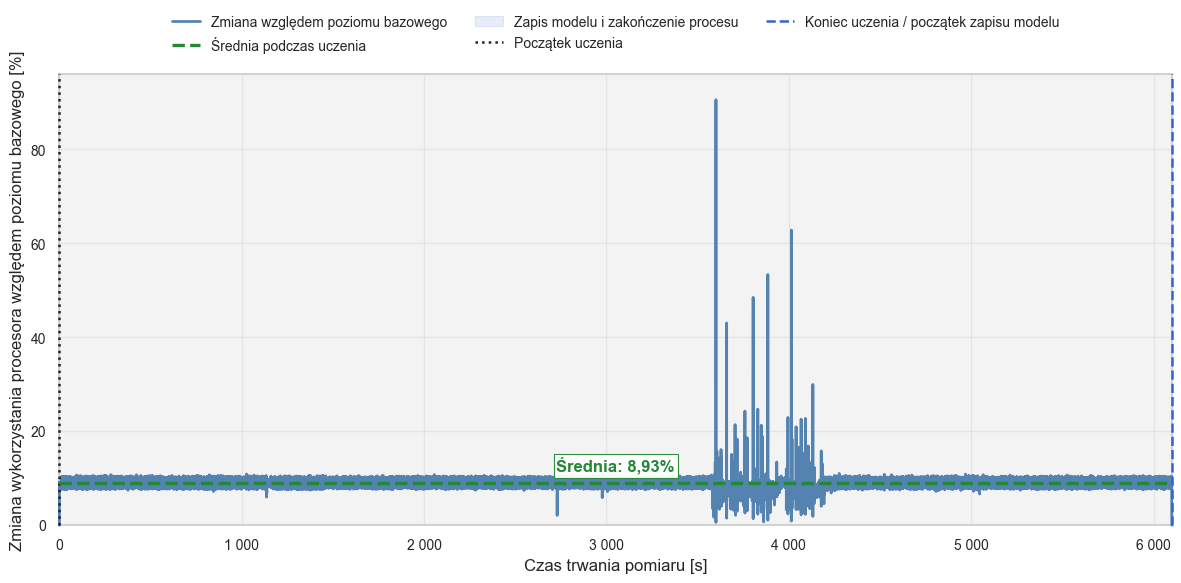

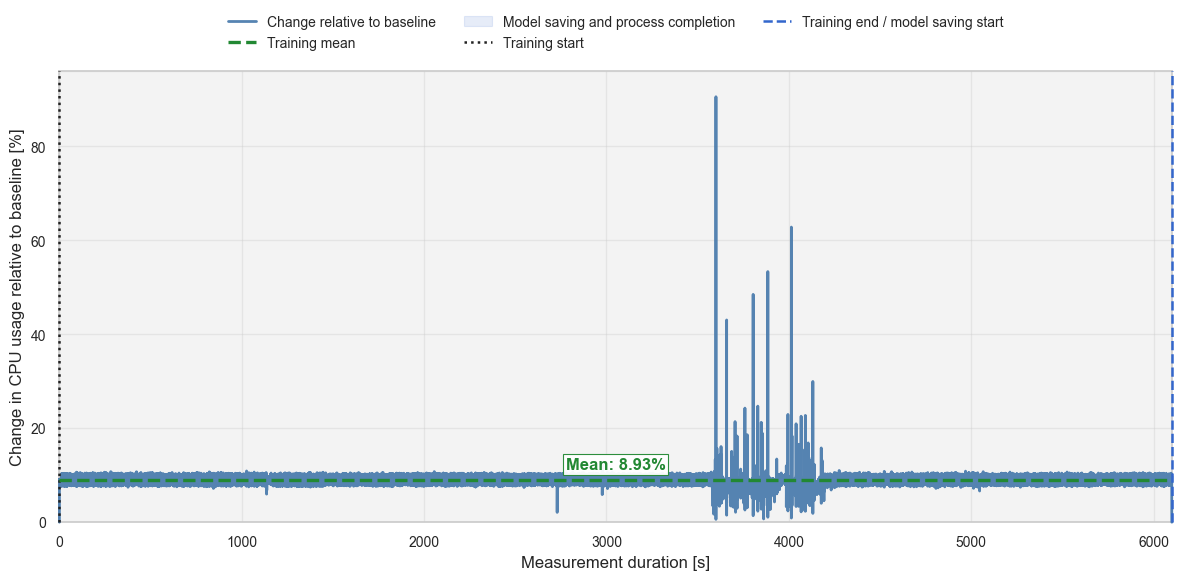

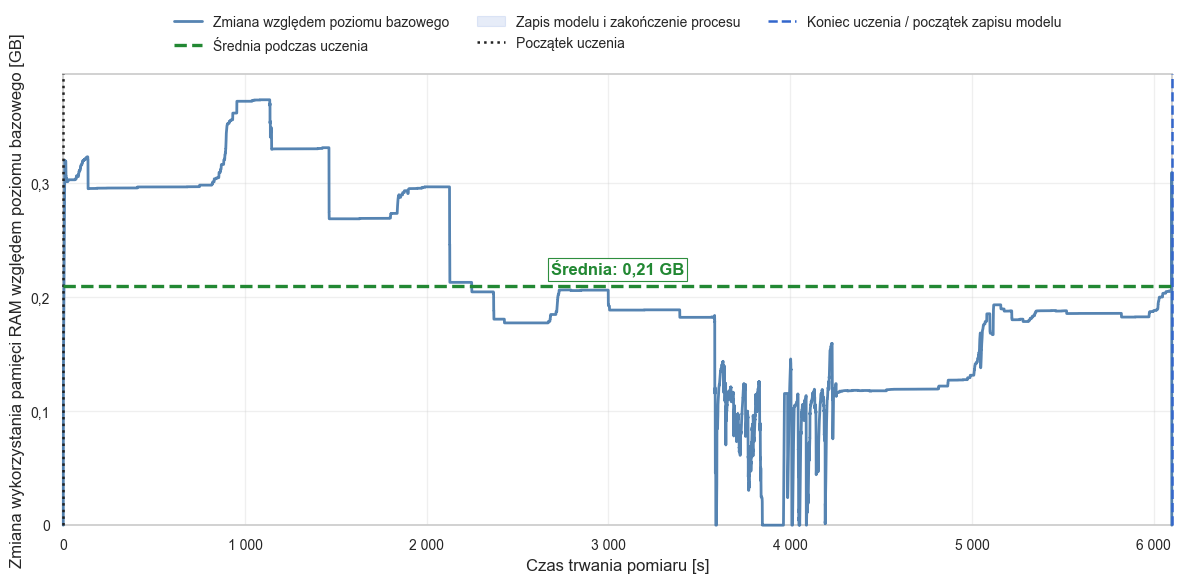

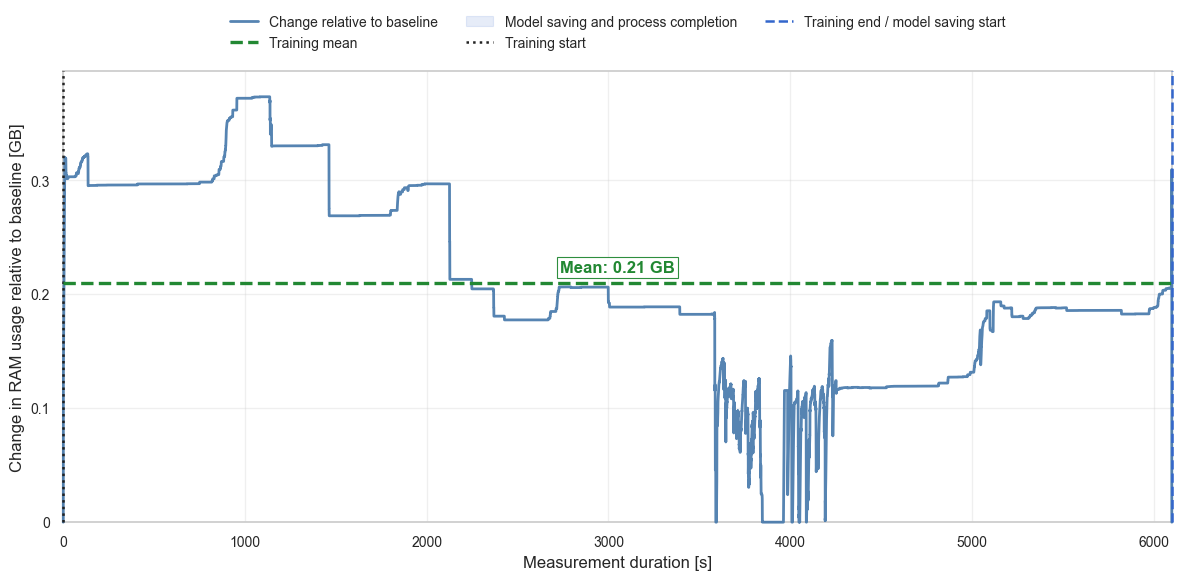

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/resource_usage/svm_full.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/svm/full/pl/svm_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/svm/full/pl/svm_resource_usage_ram.png


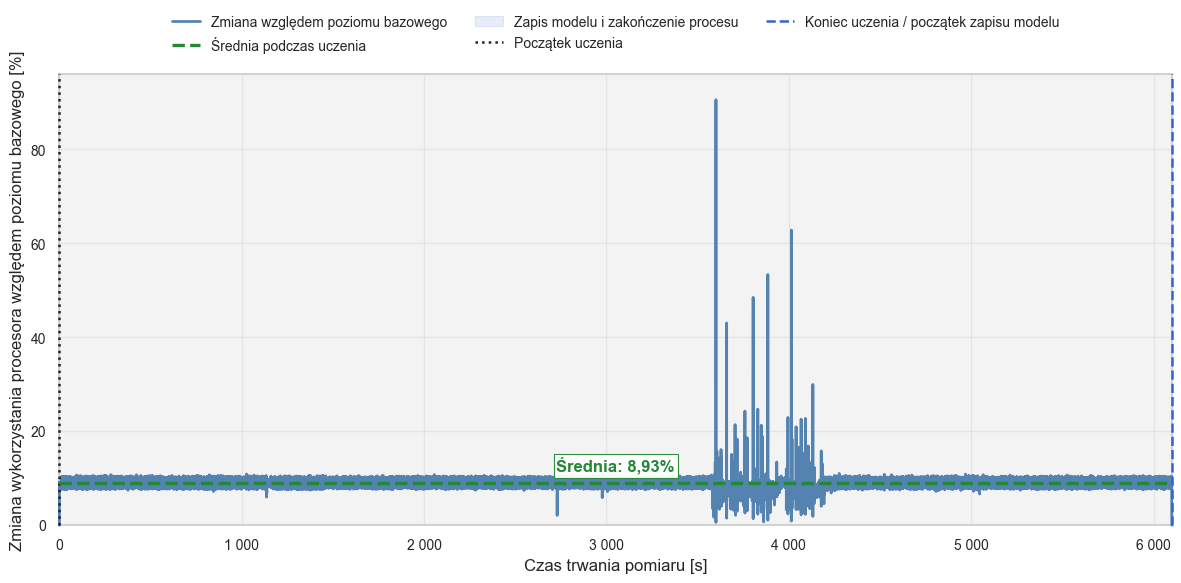

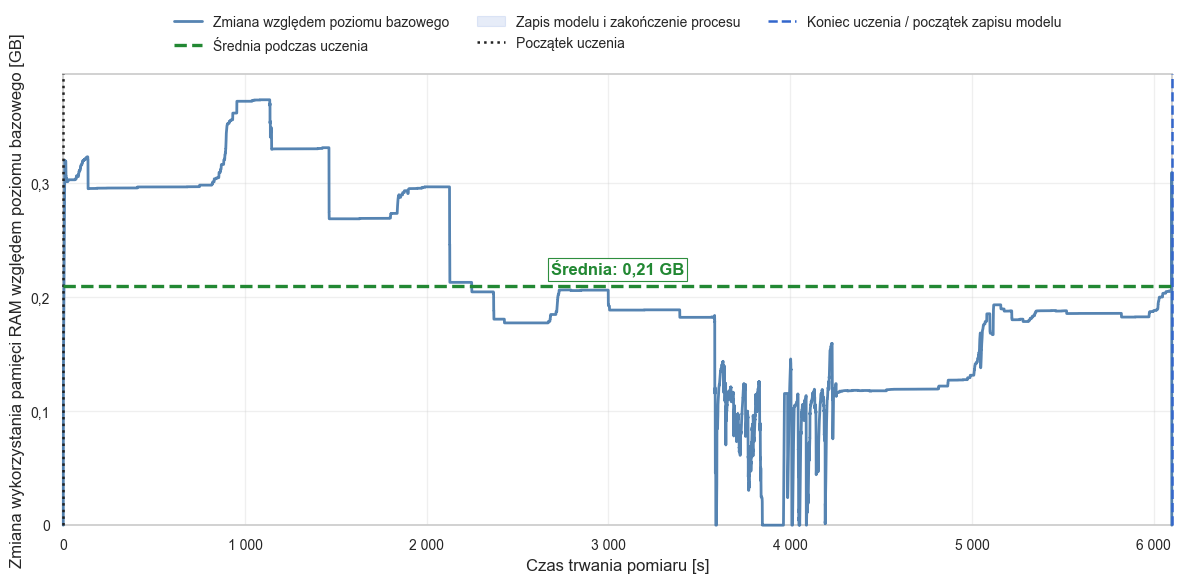

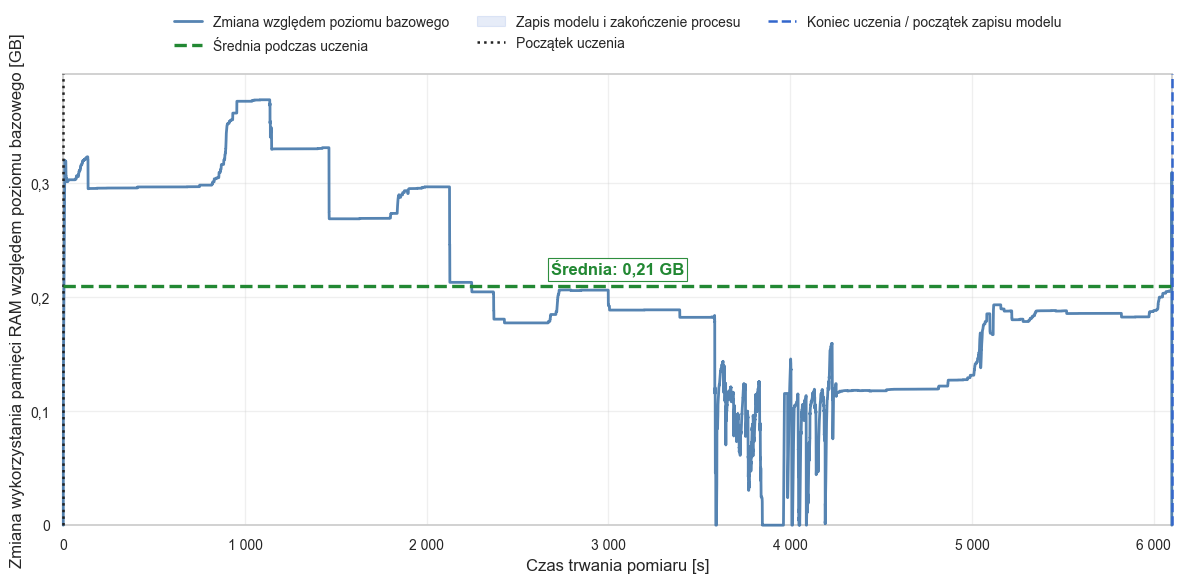

Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,03% łącznej mocy 11 rdzeni logicznych; RAM: 0,20 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


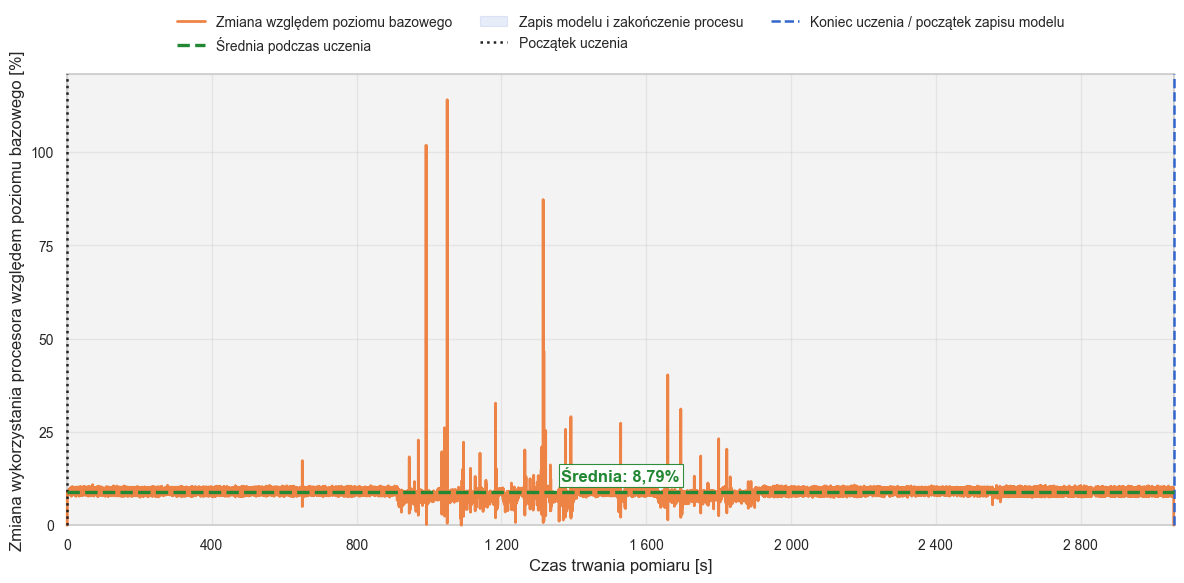

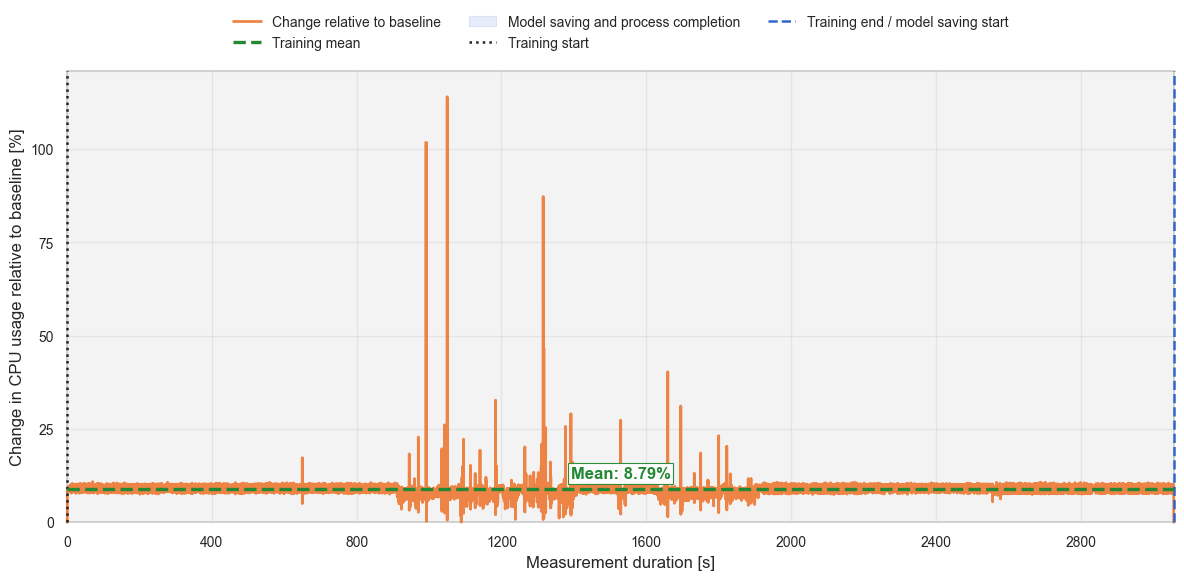

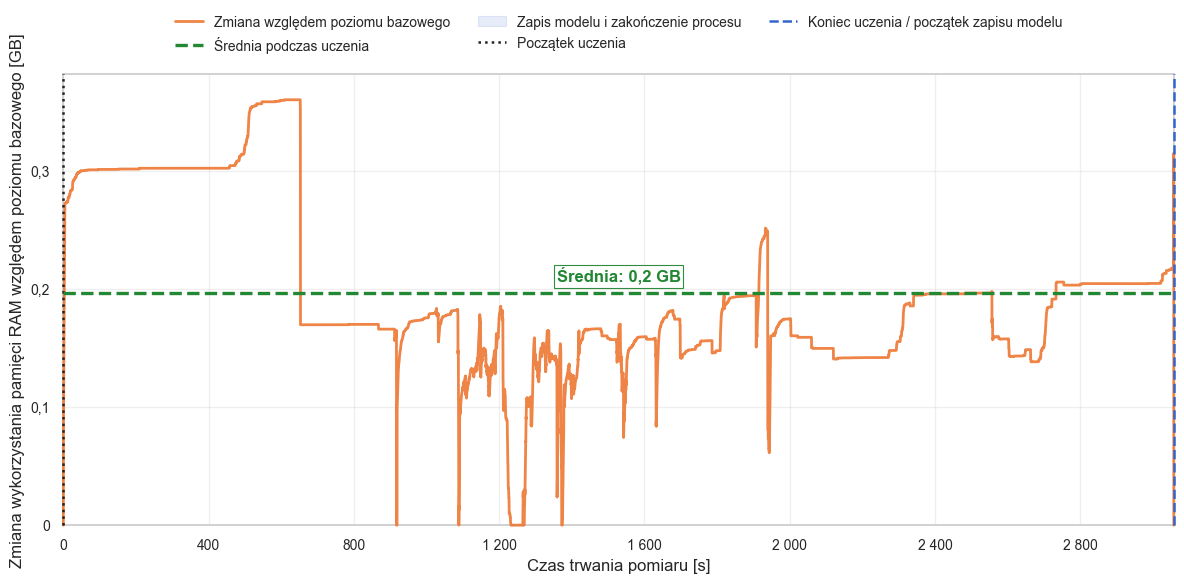

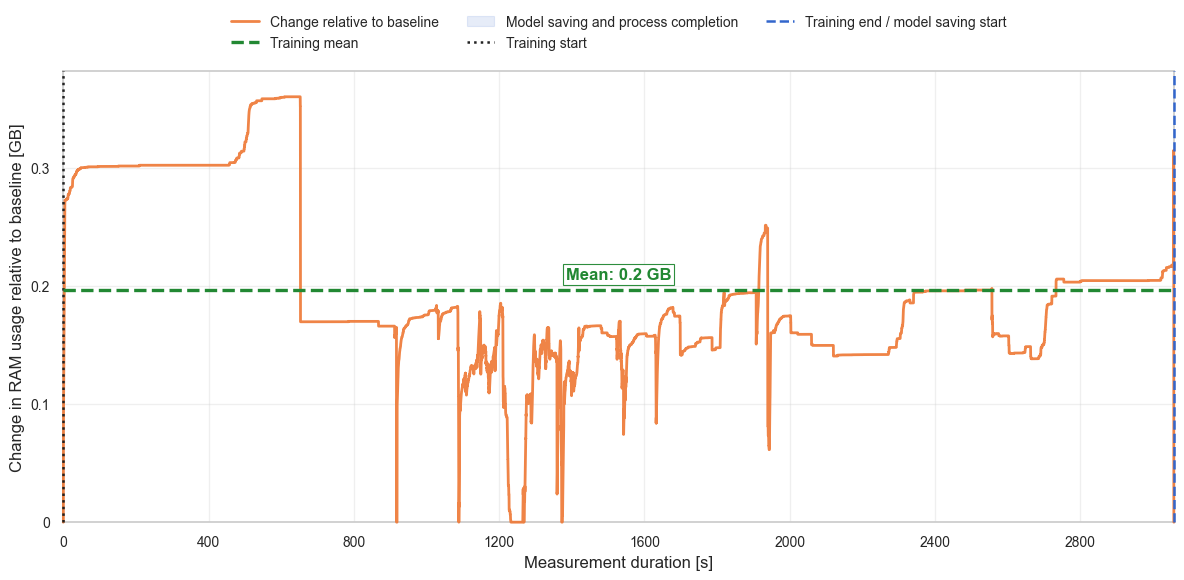

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/resource_usage/svm_optimized.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/svm/optimized/pl/svm_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/svm/optimized/pl/svm_resource_usage_ram.png


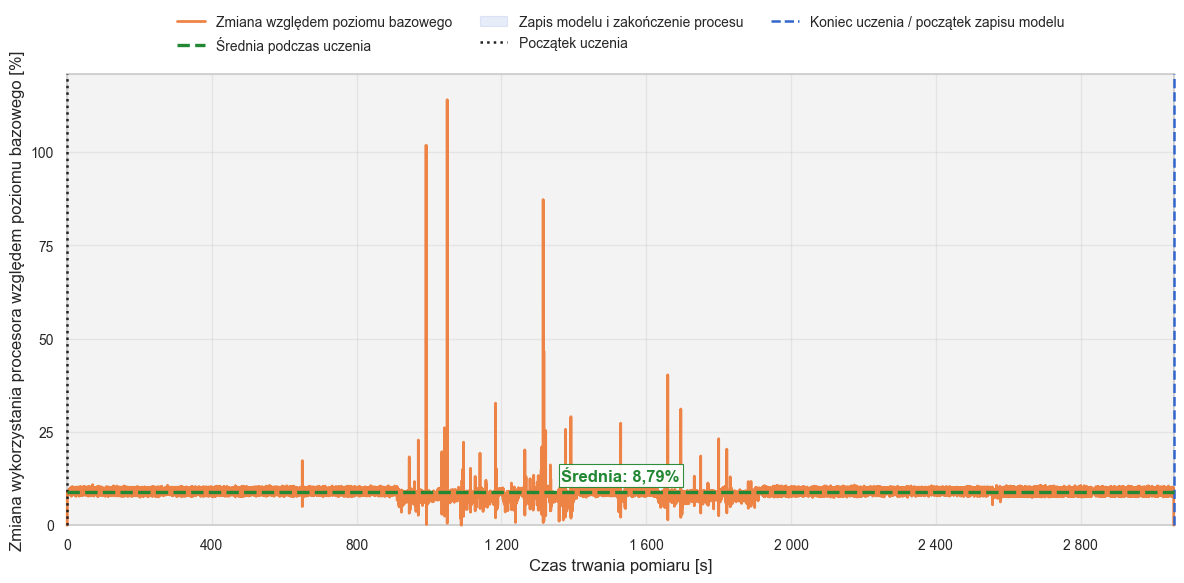

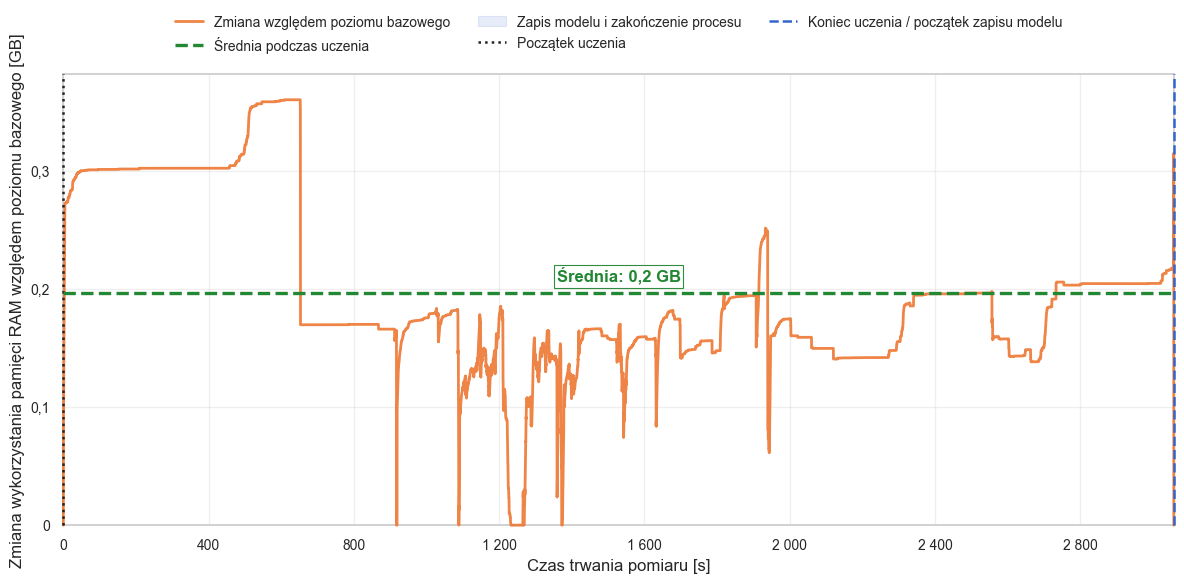

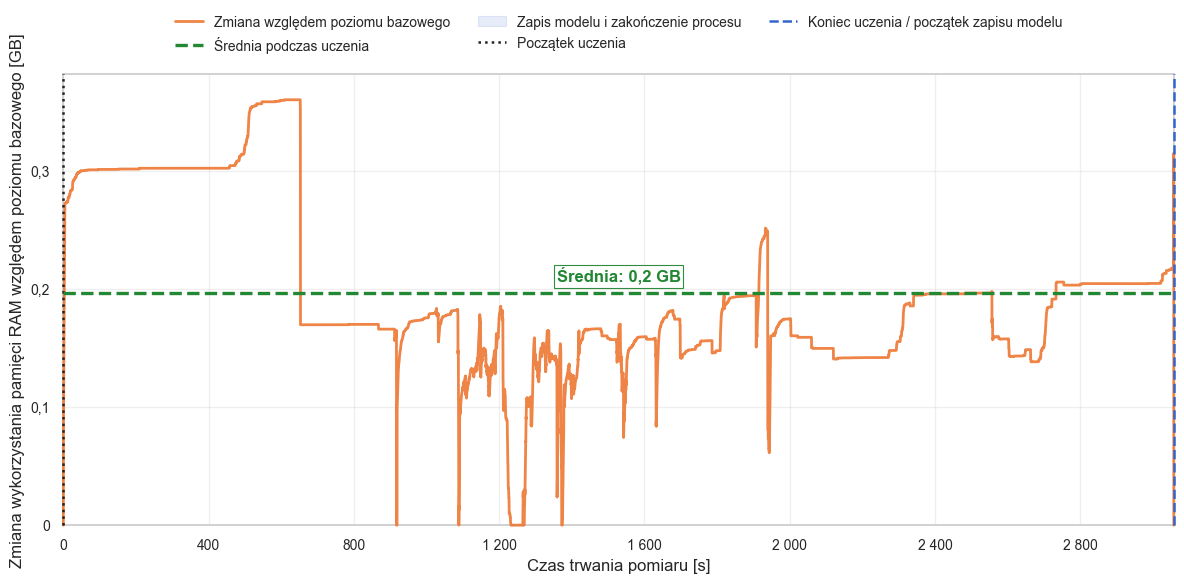

In [8]:
from IPython.display import display

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    monitor = results_for_datasets[dataset_name]['resource_monitor']
    stats = results_for_datasets[dataset_name]['resource_stats']
    print(resource_baseline_summary(monitor))
    trace_dir = backend_root.parent / 'results' / 'url_corpus' / 'resource_usage'
    trace_dir.mkdir(parents=True, exist_ok=True)
    trace_path = trace_dir / f'svm_{dataset_key(dataset_name)}.csv'
    monitor.save_phase_trace(trace_path)
    cpu_figure, ram_figure = plot_resource_usage_separate(monitor, stats, dataset_name, include_post_training=True)
    cpu_path = save_dataset_figure(cpu_figure, PLOTS_DIR, dataset_name, 'svm_resource_usage_cpu.png')
    ram_path = save_dataset_figure(ram_figure, PLOTS_DIR, dataset_name, 'svm_resource_usage_ram.png')
    print(f'Zapisano ślad: {trace_path}')
    print(f'Zapisano wykres CPU: {cpu_path}')
    print(f'Zapisano wykres RAM: {ram_path}')
    display(cpu_figure)
    display(ram_figure)
    plt.close(cpu_figure)
    plt.close(ram_figure)
    plt.show()


## 6. Porównanie wyników uczenia i testowania

Miary dla procesu uczenia obliczane są na zbiorze uczącym, a miary testowe na
niezależnym zbiorze testowym. Każda miara jest prezentowana na osobnym wykresie
i wykorzystuje wyniki uzyskane przez wytrenowany model, bez jego ponownego
uczenia na potrzeby wizualizacji.

Walidacja oznacza ocenę modelu na danych, które nie uczestniczyły w jego
dopasowaniu w danym przebiegu, ale nadal należą do części danych przeznaczonej
do opracowania modelu. Nie jest ona testem końcowym. Dla każdego rozmiaru
podzbioru uczącego linia uczenia i linia walidacji przedstawiają średnią z pięciu
przebiegów, a półprzezroczyste pasmo przedstawia jedno odchylenie standardowe.
Niezależny zbiór testowy nie uczestniczy w wyznaczaniu tych krzywych.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.



EWALUACJA MODELU - PEŁNY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.8882
  • Precyzja: 0.9731
  • Czułość: 0.7985
  • Współczynnik fałszywie dodatnich (FPR): 0.0221 (2.21%)
  • Próg skalibrowany na walidacji: 0.8931
  • Walidacyjny FPR przy wybranym progu: 1.96%
  • Walidacyjna czułość przy wybranym progu: 84.71%
  • Docelowy FPR kalibracji: 2.00%
  • Miara F1 (F1-Score): 0.8772
  • AUC-ROC: 0.9642
  • Błąd uczenia: 0.0666
  • Błąd testowania: 0.1118


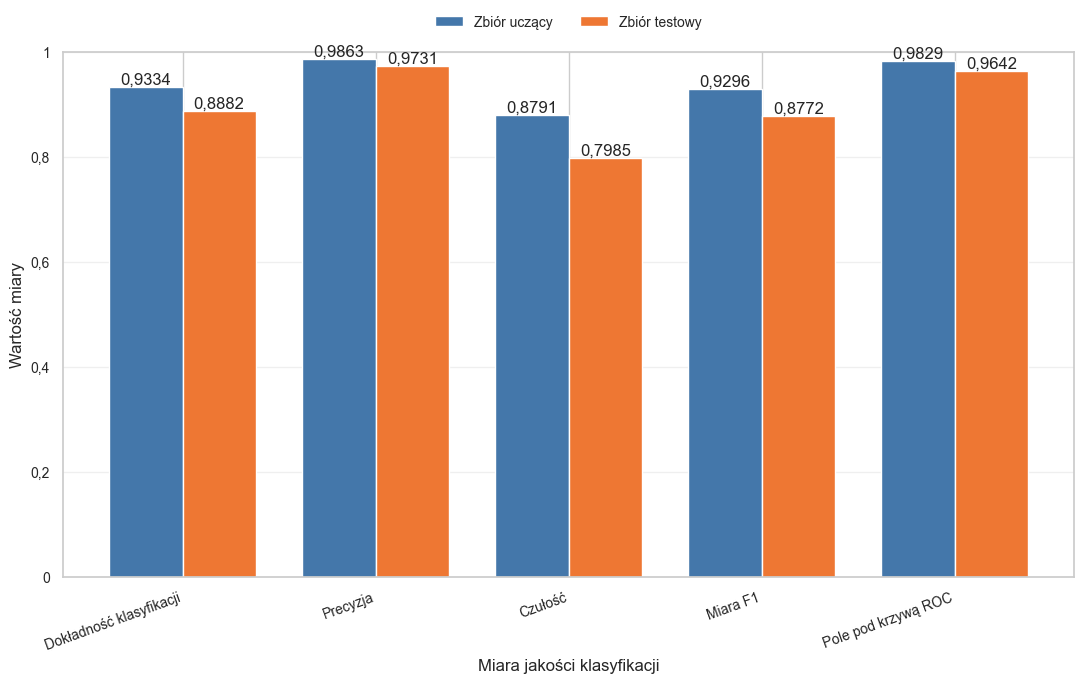

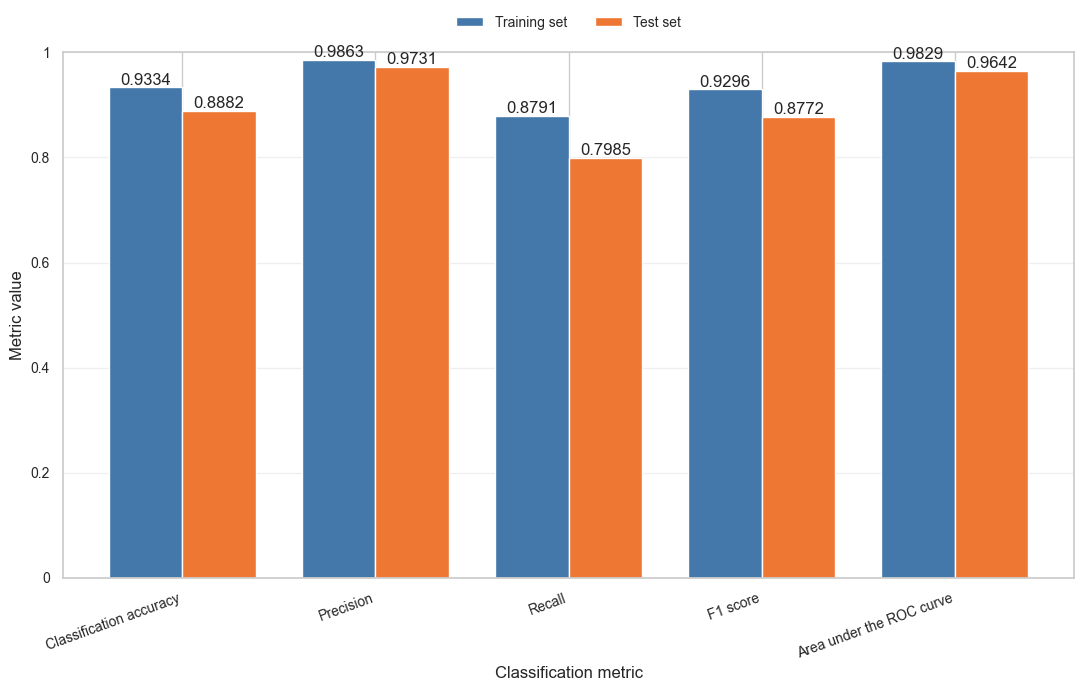

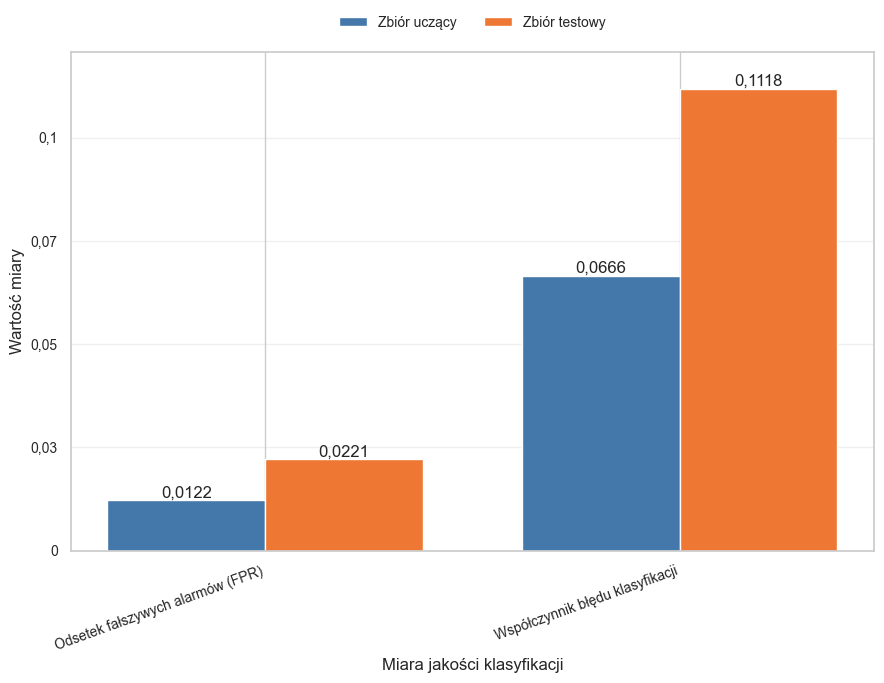

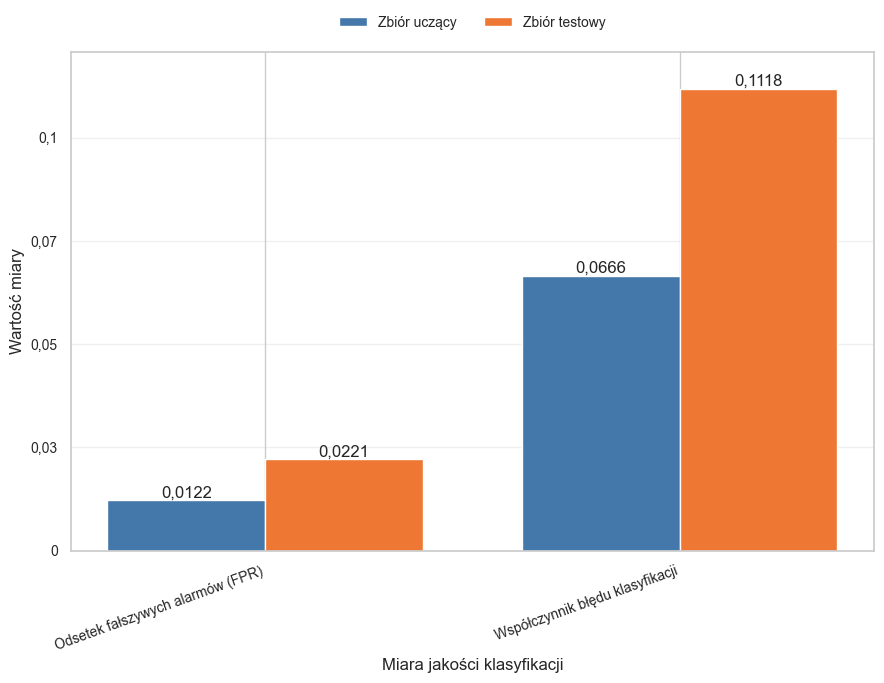

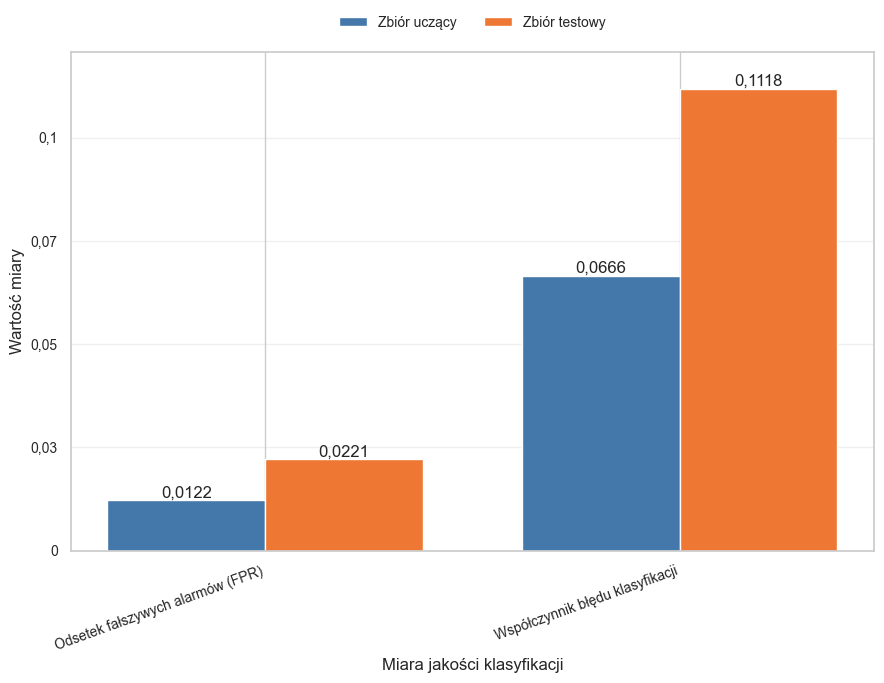

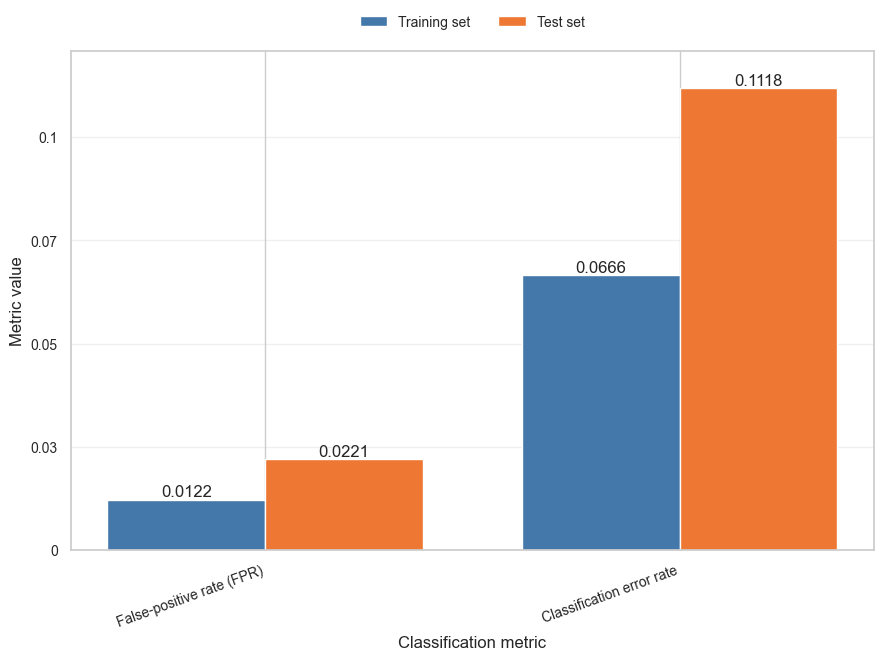


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,268
  • Fałszywie pozytywne (FP): 232
  • Fałszywie negatywne (FN): 2,116
  • Prawdziwie pozytywne (TP): 8,384

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9800 ± 0.0004
  • Min: 0.9794
  • Max: 0.9806

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.8864
  • Precyzja: 0.9721
  • Czułość: 0.7957
  • Współczynnik fałszywie dodatnich (FPR): 0.0229 (2.29%)
  • Próg skalibrowany na walidacji: 0.8926
  • Walidacyjny FPR przy wybranym progu: 1.98%
  • Walidacyjna czułość przy wybranym progu: 82.50%
  • Docelowy FPR kalibracji: 2.00%
  • Miara F1 (F1-Score): 0.8751
  • AUC-ROC: 0.9532
  • Błąd uczenia: 0.0686
  • Błąd testowania: 0.1136


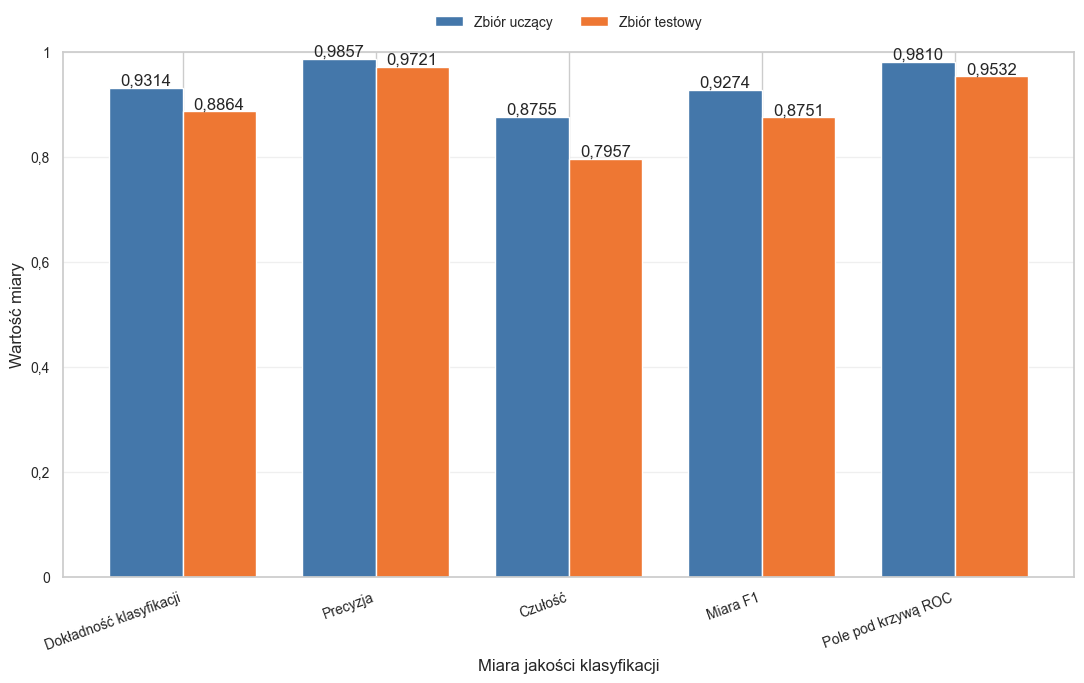

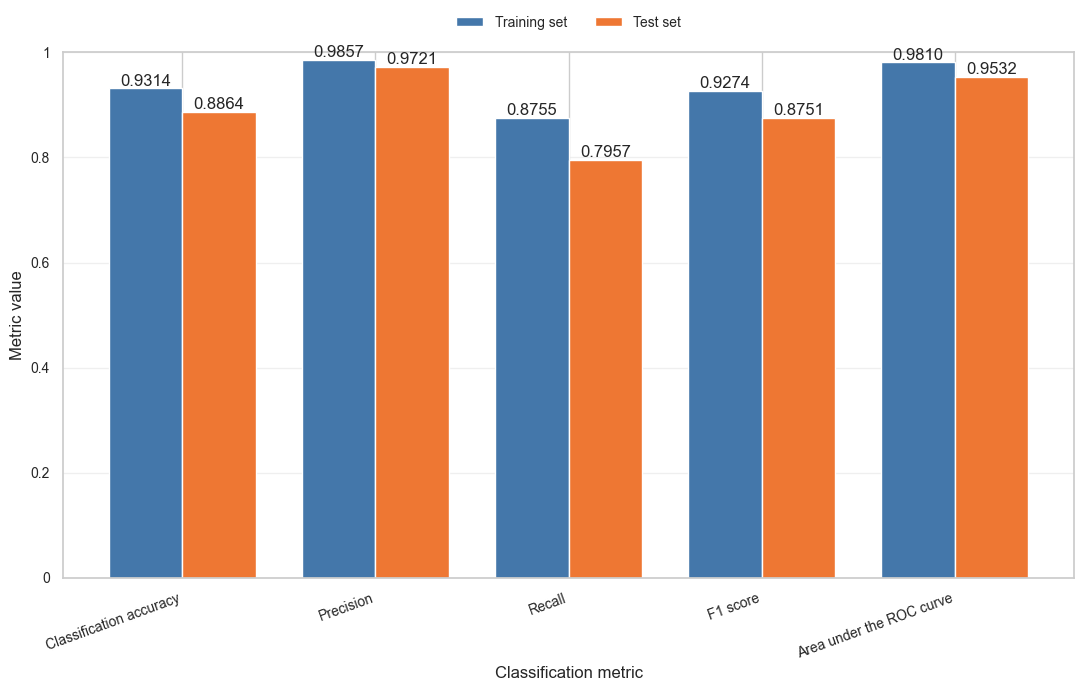

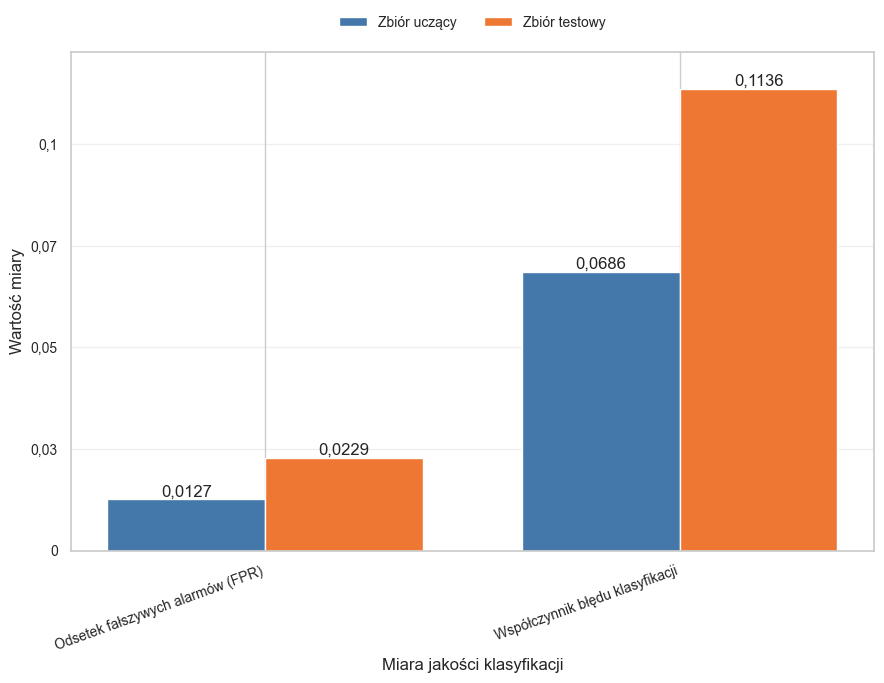

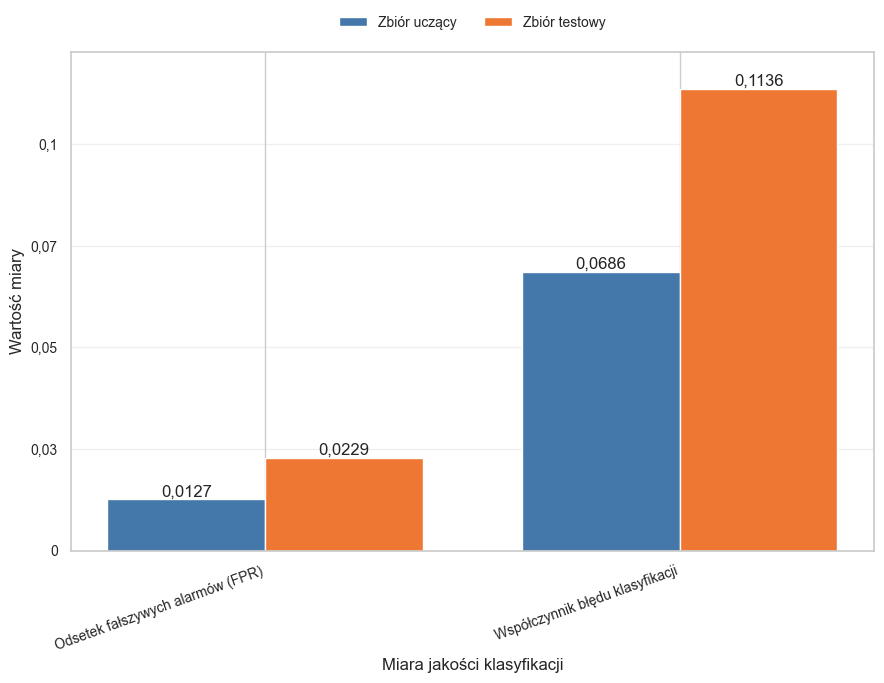

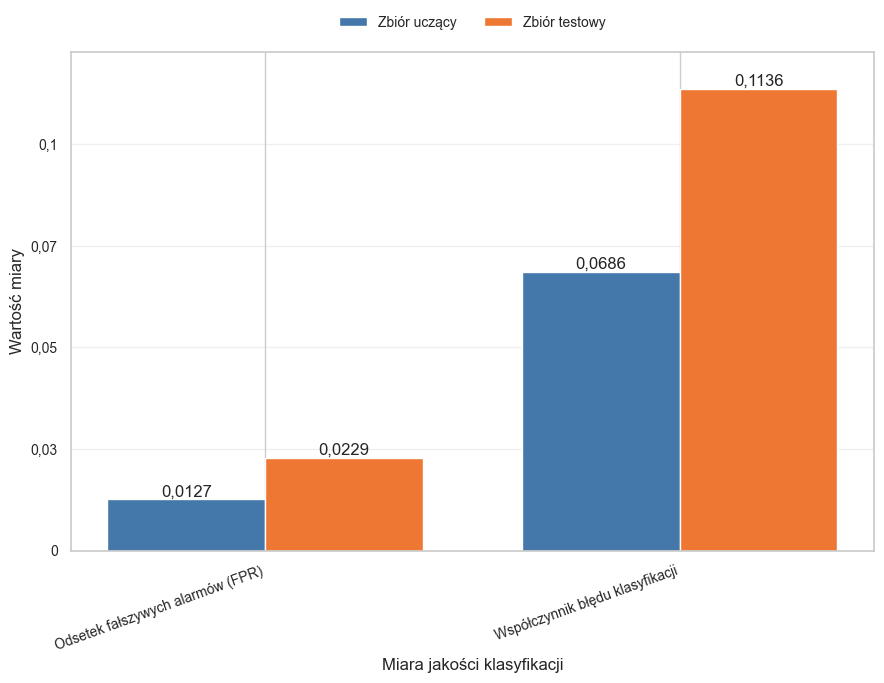

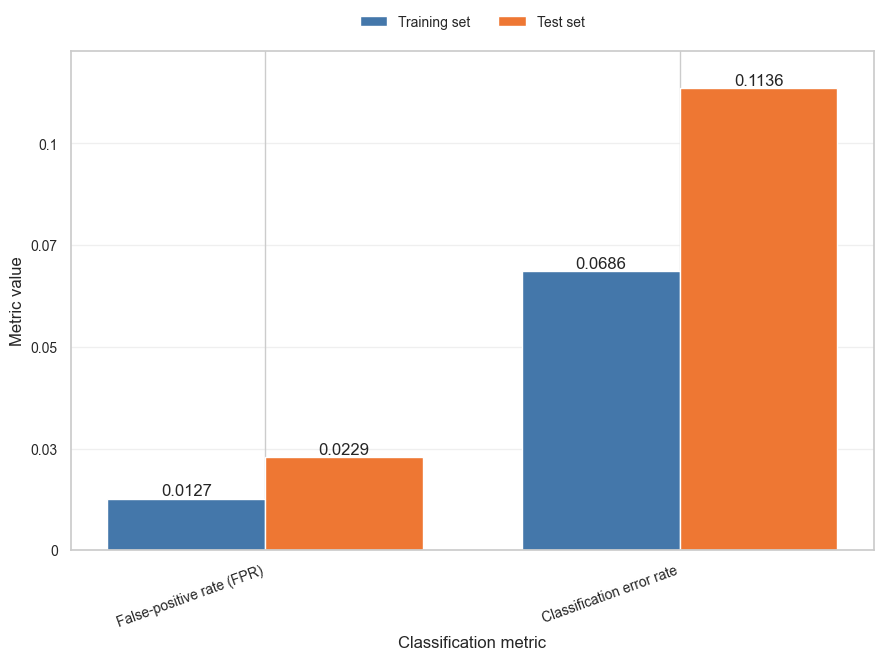


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,260
  • Fałszywie pozytywne (FP): 240
  • Fałszywie negatywne (FN): 2,145
  • Prawdziwie pozytywne (TP): 8,355

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9784 ± 0.0008
  • Min: 0.9774
  • Max: 0.9794

PORÓWNANIE WYNIKÓW
Metryka                  Pełny zbiór Zoptymalizowany zbiór
--------------------------------------------------------------------------------
Accuracy                      0.8882          0.8864 (-0.0018)
Precision                     0.9731          0.9721 (-0.0010)
Recall                        0.7985          0.7957 (-0.0028)
False_positive_rate           0.0221          0.0229 (+0.0008)
F1                            0.8772          0.8751 (-0.0021)
Auc_roc                       0.9642          0.9532 (-0.0110)


In [9]:
evaluation_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    X_train = results_for_datasets[dataset_name]['X_train_scaled']
    X_test = results_for_datasets[dataset_name]['X_test_scaled']
    y_train = results_for_datasets[dataset_name]['y_train']
    y_test = results_for_datasets[dataset_name]['y_test']

    y_val_proba = predict_probabilities(model, data_splits[dataset_name]['X_val_scaled'])
    threshold_info = calibrate_threshold(
        data_splits[dataset_name]['y_val'], y_val_proba,
        max_false_positive_rate=DEFAULT_MAX_FALSE_POSITIVE_RATE,
        min_recall=DEFAULT_MIN_RECALL,
    )
    decision_threshold = threshold_info['threshold']
    y_pred_proba = predict_probabilities(model, X_test)
    y_pred = (y_pred_proba >= decision_threshold).astype(int)
    y_train_proba = predict_probabilities(model, X_train)
    y_train_pred = (y_train_proba >= decision_threshold).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0

    train_cm = confusion_matrix(y_train, y_train_pred)
    train_tn, train_fp, train_fn, train_tp = train_cm.ravel()
    train_false_positive_rate = train_fp / (train_fp + train_tn) if (train_fp + train_tn) else 0.0
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_precision = precision_score(y_train, y_train_pred)
    train_recall = recall_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred)
    accuracy = accuracy_score(y_test, y_pred)
    train_error_rate = 1.0 - accuracy_score(y_train, y_train_pred)
    test_error_rate = 1.0 - accuracy
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    train_auc_roc = roc_auc_score(y_train, y_train_proba)
    train_bce = log_loss(y_train, y_train_proba)
    test_bce = log_loss(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'train_accuracy': train_accuracy,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_false_positive_rate': train_false_positive_rate,
        'train_f1': train_f1,
        'accuracy': accuracy,
        'train_error_rate': train_error_rate,
        'test_error_rate': test_error_rate,
        'precision': precision,
        'recall': recall,
        'false_positive_rate': false_positive_rate,
        'decision_threshold': decision_threshold,
        'threshold_calibration': threshold_info,
        'f1': f1,
        'auc_roc': auc_roc,
        'train_auc_roc': train_auc_roc,
        'train_bce': train_bce,
        'test_bce': test_bce,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja: {precision:.4f}")
    print(f"  • Czułość: {recall:.4f}")
    print(f"  • Współczynnik fałszywie dodatnich (FPR): {false_positive_rate:.4f} ({false_positive_rate:.2%})")
    print(f"  • Próg skalibrowany na walidacji: {decision_threshold:.4f}")
    print(f"  • Walidacyjny FPR przy wybranym progu: {threshold_info['validation_fpr']:.2%}")
    print(f"  • Walidacyjna czułość przy wybranym progu: {threshold_info['validation_recall']:.2%}")
    print(f"  • Docelowy FPR kalibracji: {threshold_info['target_fpr']:.2%}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")
    print(f"  • Błąd uczenia: {train_error_rate:.4f}")
    print(f"  • Błąd testowania: {test_error_rate:.4f}")

    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'svm_final_error_rate.png'
    )

    train_metrics, test_metrics = classification_metric_sets(
        evaluation_results[dataset_name]
    )
    metric_figures = plot_final_train_test_metric_groups(
        train_metrics, test_metrics
    )
    for group_name, metric_figure in metric_figures.items():
        save_dataset_figure(
            metric_figure, PLOTS_DIR, dataset_name,
            f'svm_metrics_{group_name}.png',
        )
        plt.show()

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'false_positive_rate', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")

## 7. Wizualizacja kompleksowa i krzywa uczenia


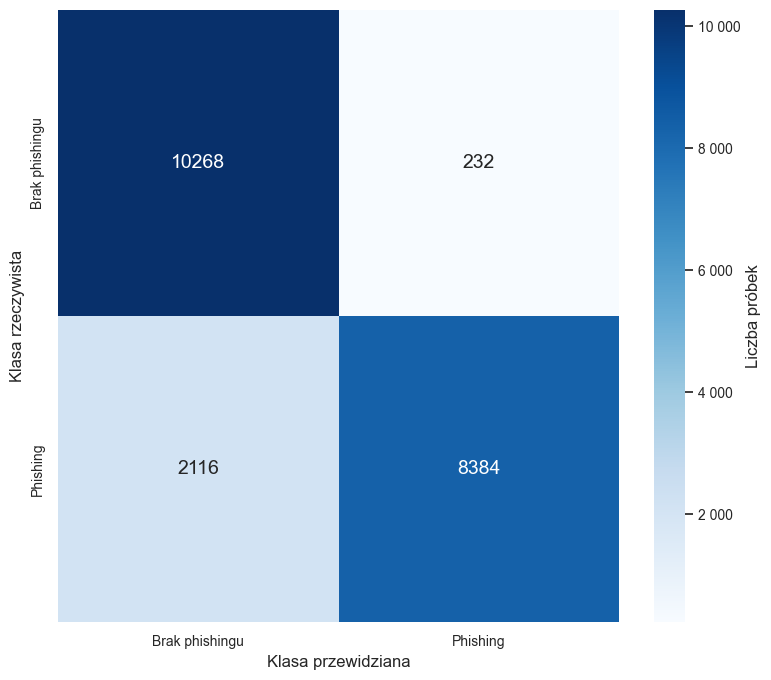

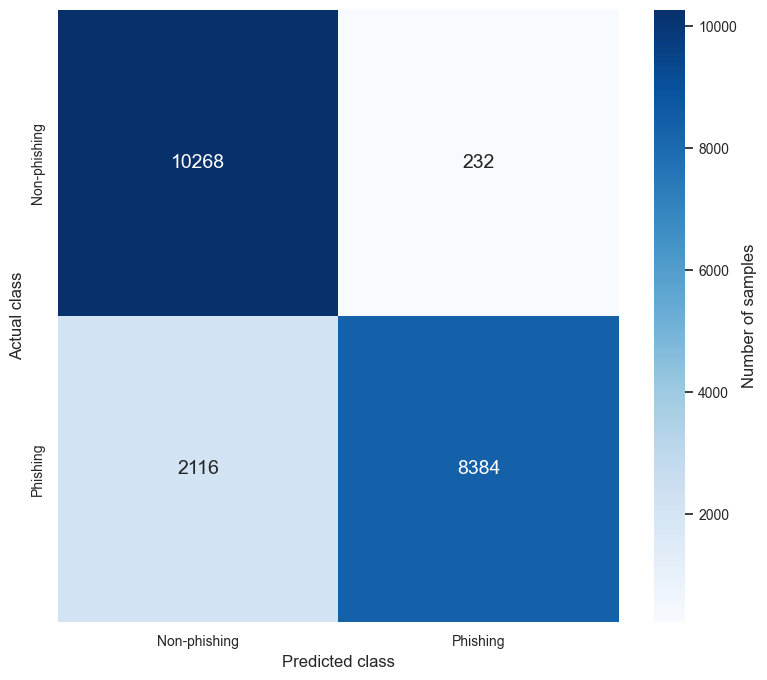

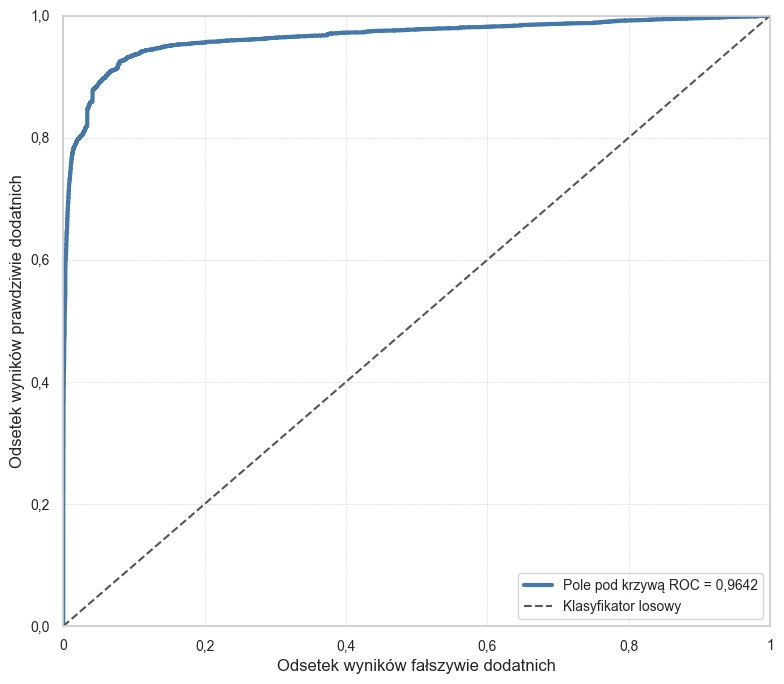

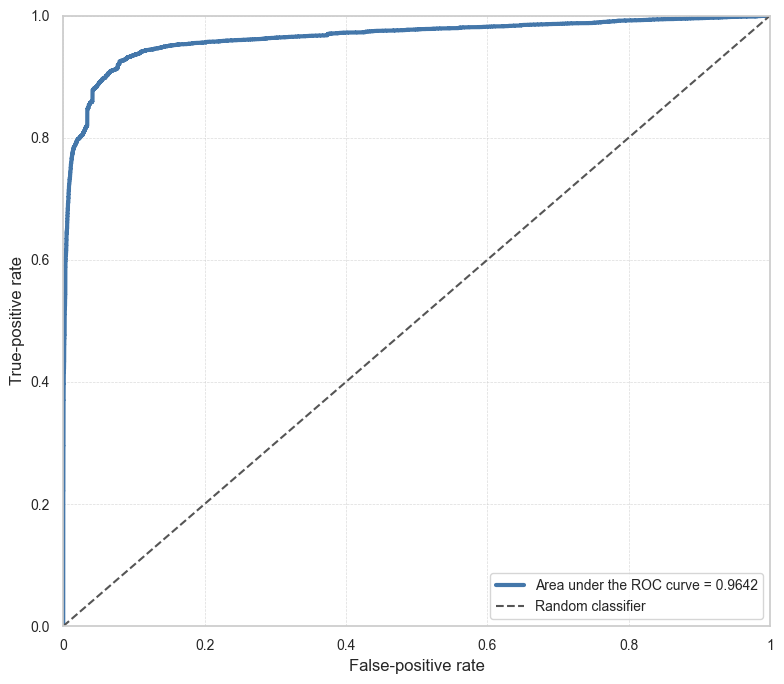

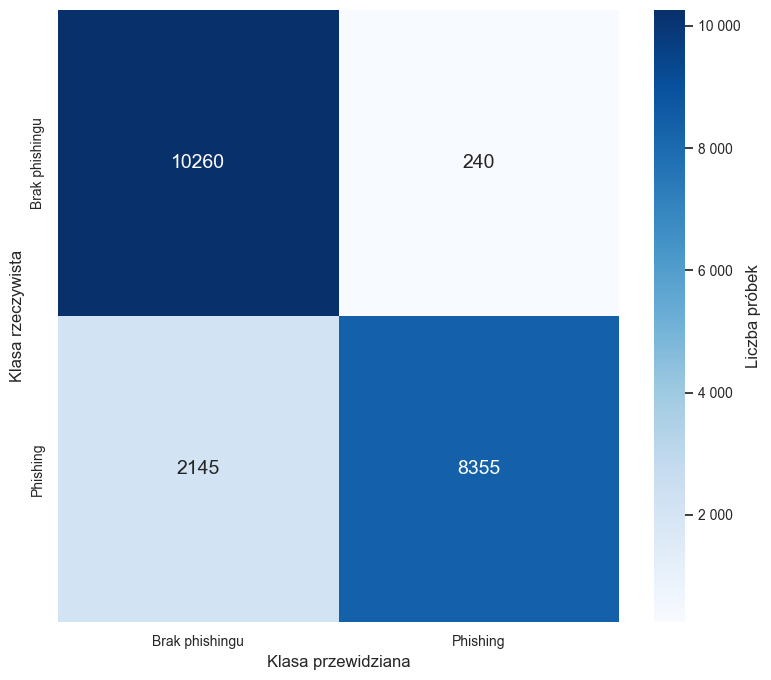

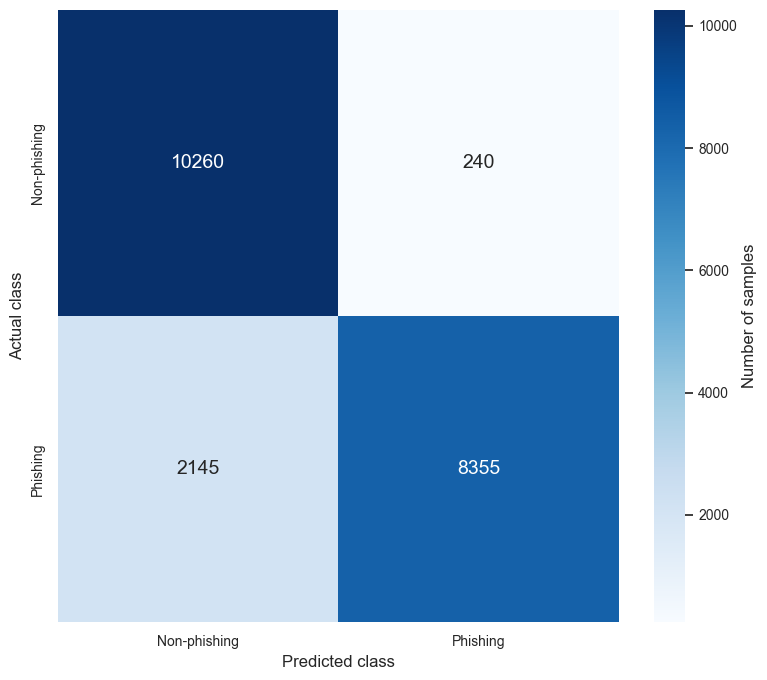

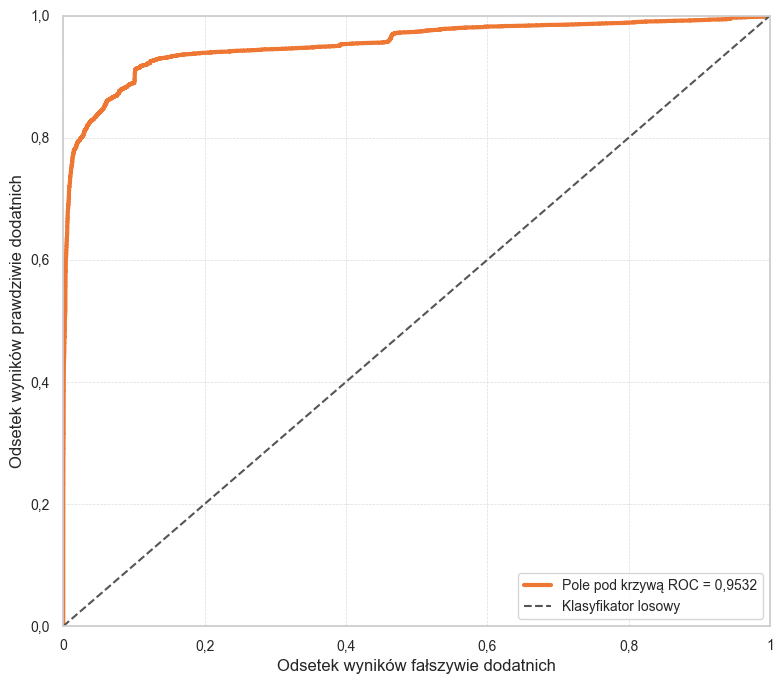

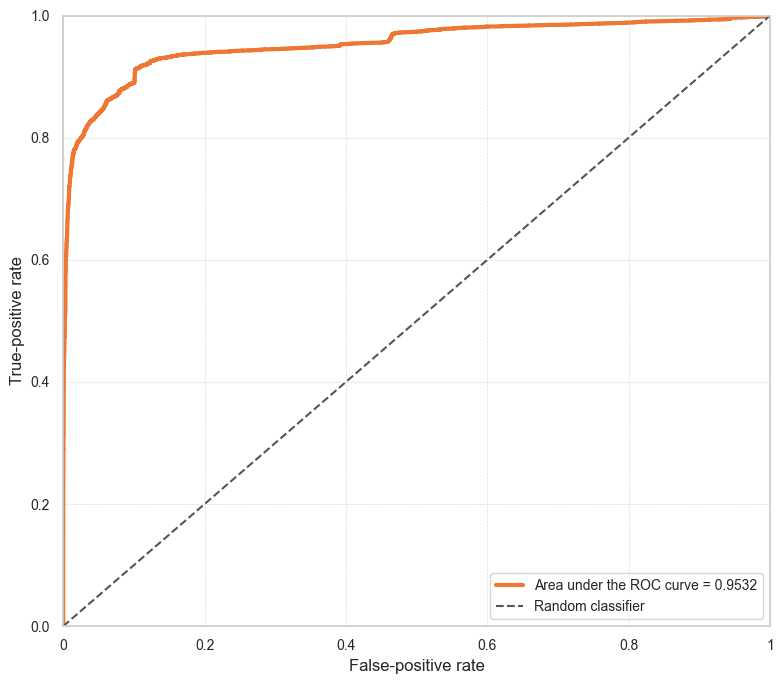

In [10]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    evaluation = evaluation_results[dataset_name]

    confusion_figure, _ = plot_confusion_matrix(
        evaluation['confusion_matrix'], dataset_name,
    )
    save_dataset_figure(
        confusion_figure, PLOTS_DIR, dataset_name, 'svm_confusion_matrix.png'
    )
    plt.show()

    roc_figure, _ = plot_roc_curve(
        data_splits[dataset_name]['y_test'], evaluation['y_pred_proba'], evaluation['auc_roc'], dataset_name,
    )
    save_dataset_figure(
        roc_figure, PLOTS_DIR, dataset_name, 'svm_roc_curve.png'
    )
    plt.show()


## 7.1. Porównanie metryk w postaci wykresów słupkowych


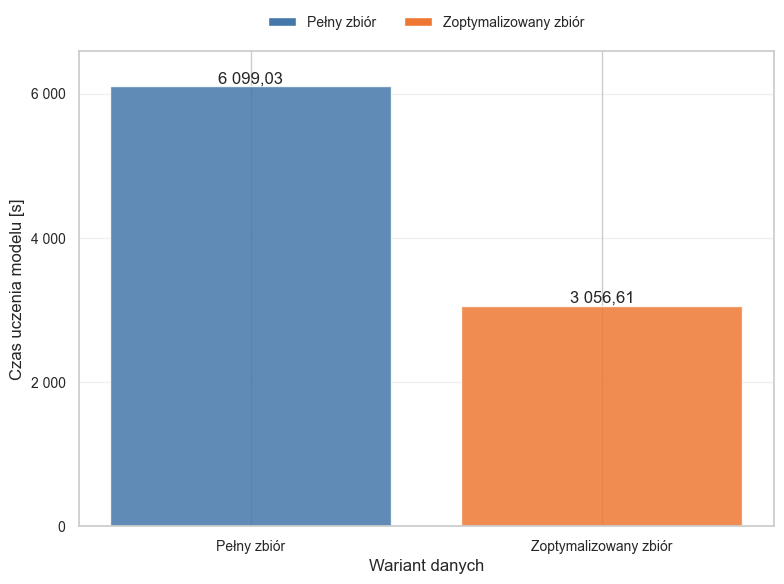

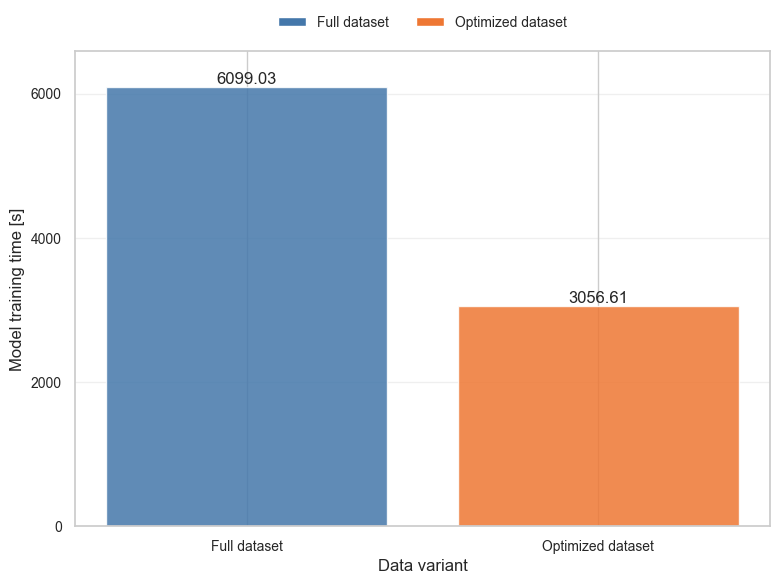

,Wariant danych,Liczba cech,Redukcja liczby cech,Redukcja [%]
0,Pełny zbiór,110,0,0.00
1,Zoptymalizowany zbiór,47,63,57.27


In [11]:
training_times = {}
feature_counts = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    training_times[dataset_name] = float(results_for_datasets[dataset_name]['training_time'])
    feature_counts[dataset_name] = int(len(data_splits[dataset_name]['X'].columns))
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'svm_training_time.png'
    )
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'svm_feature_count.png'
    )

time_figure, _ = plot_training_time_comparison(training_times)
save_comparison_figure(
    time_figure, PLOTS_DIR / 'svm_training_time_comparison.png'
)
plt.show()

feature_count_rows = feature_count_comparison_rows(
    feature_counts['Pełny zbiór'],
    feature_counts['Zoptymalizowany zbiór'],
)
display(pd.DataFrame(feature_count_rows))


## 7.1a. Ścieżka decyzyjna dla przykładowego URL


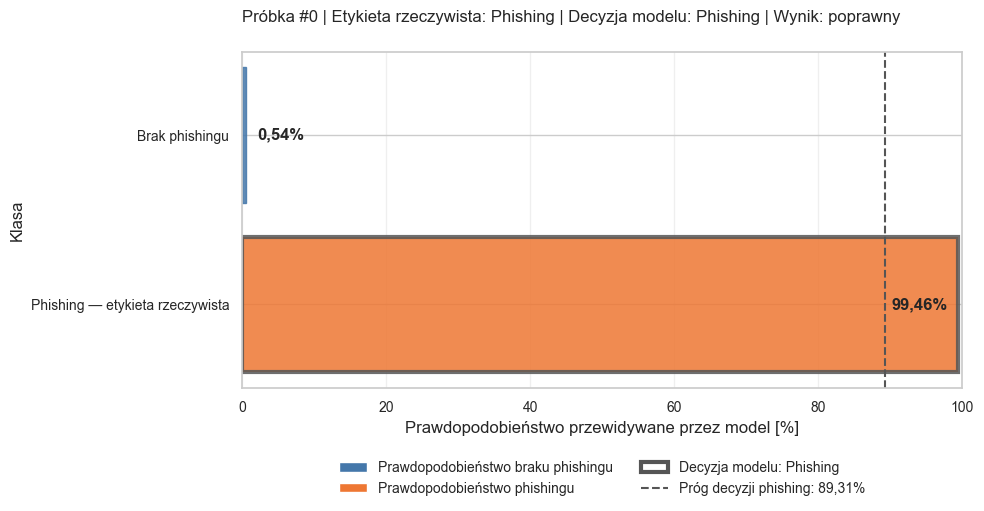

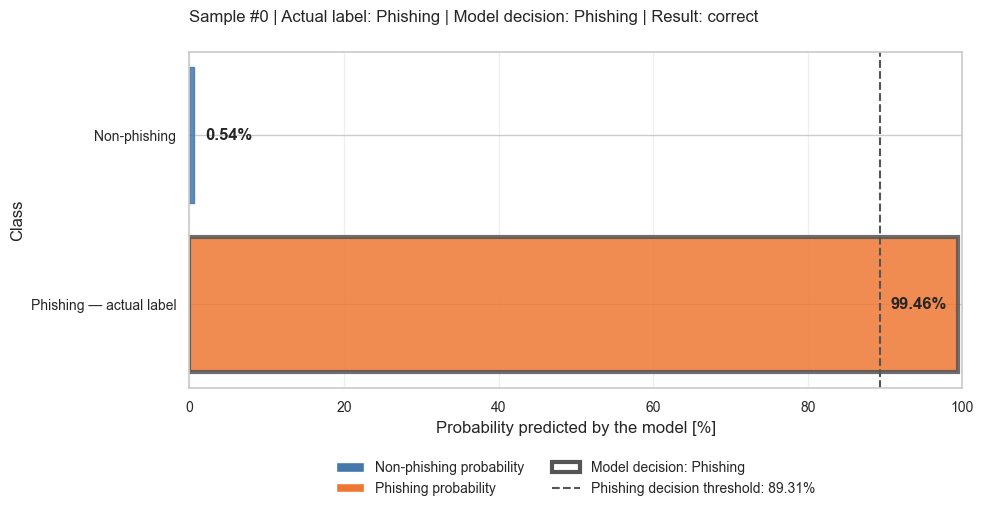

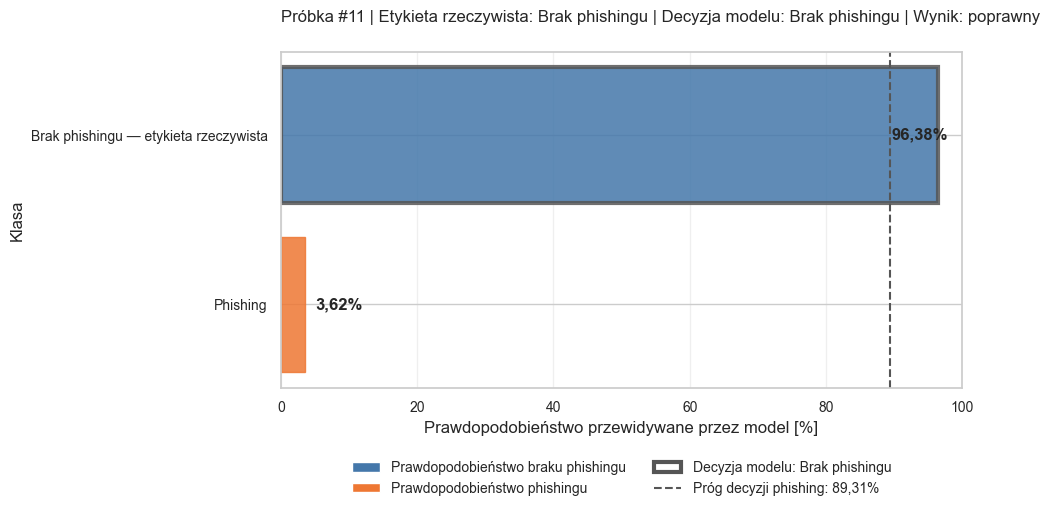

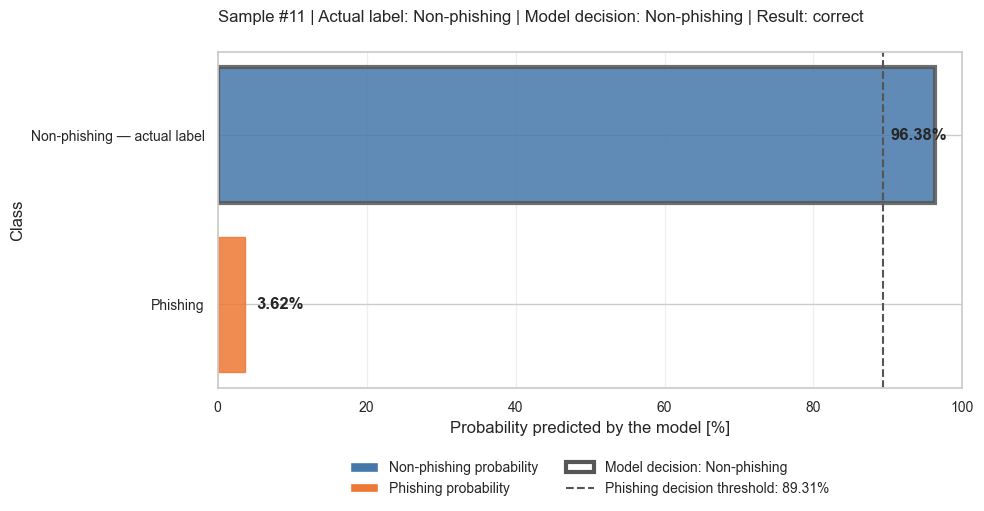

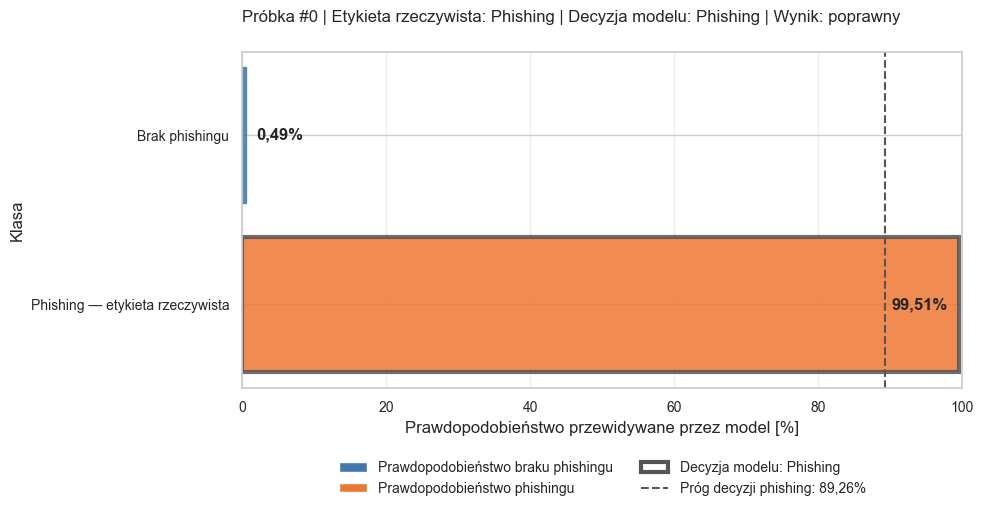

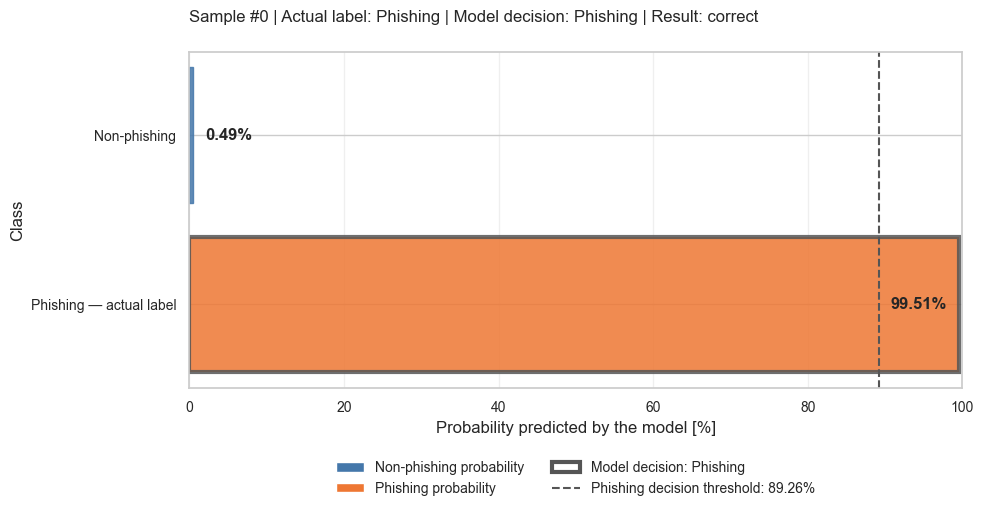

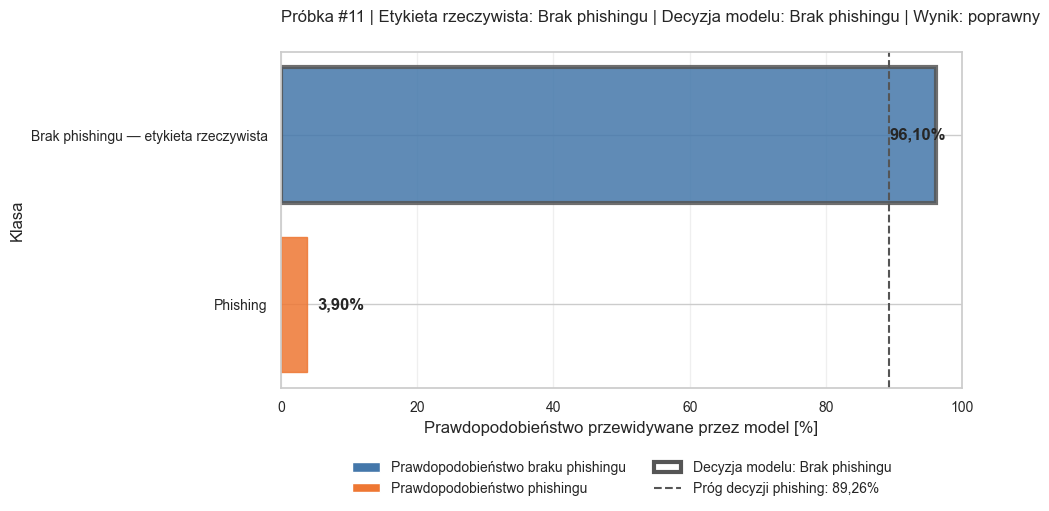

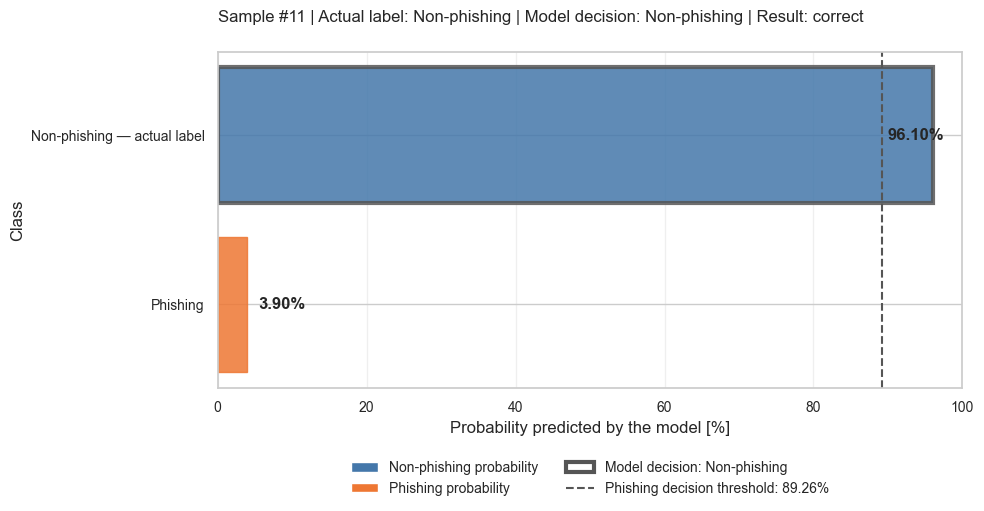

In [12]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    true_labels = data_splits[dataset_name]['y_test']
    label_values = np.asarray(true_labels, dtype=int)
    probabilities = np.asarray(
        evaluation_results[dataset_name]['y_pred_proba'], dtype=float
    ).reshape(-1)
    threshold = evaluation_results[dataset_name].get('decision_threshold', 0.5)
    sample_positions = {
        'phishing': int(np.flatnonzero(label_values == 1)[0]),
        'bez_phishingu': int(np.flatnonzero(label_values == 0)[0]),
    }
    for sample_kind, position in sample_positions.items():
        sample_id = (
            true_labels.index[position]
            if hasattr(true_labels, 'index') else position
        )
        for language in ['pl', 'en']:
            language_folder = 'pl' if language == 'pl' else 'eng'
            figure, _ = plot_sample_probability_prediction(
                probabilities[position], label_values[position], sample_id,
                decision_threshold=threshold, language=language,
            )
            save_dataset_figure(
                figure, PLOTS_DIR, dataset_name,
                f'{language_folder}/svm_sample_prediction_{sample_kind}.png',
            )
            plt.show()
    for obsolete_name in [
        'svm_prediction_example_phishing.png',
        'svm_prediction_example_bez_phishingu.png',
        'svm_prediction_examples.png',
        'svm_probability_distribution.png',
        'svm_sample_prediction_phishing.png',
        'svm_sample_prediction_bez_phishingu.png',
        'svm_sample_prediction_phishing_pl.png',
        'svm_sample_prediction_phishing_en.png',
        'svm_sample_prediction_bez_phishingu_pl.png',
        'svm_sample_prediction_bez_phishingu_en.png',
    ]:
        remove_dataset_figure(PLOTS_DIR, dataset_name, obsolete_name)


## 7.1b. Wizualizacja architektury SVM


Obliczanie permutation importance dla architektury Pełny zbiór...


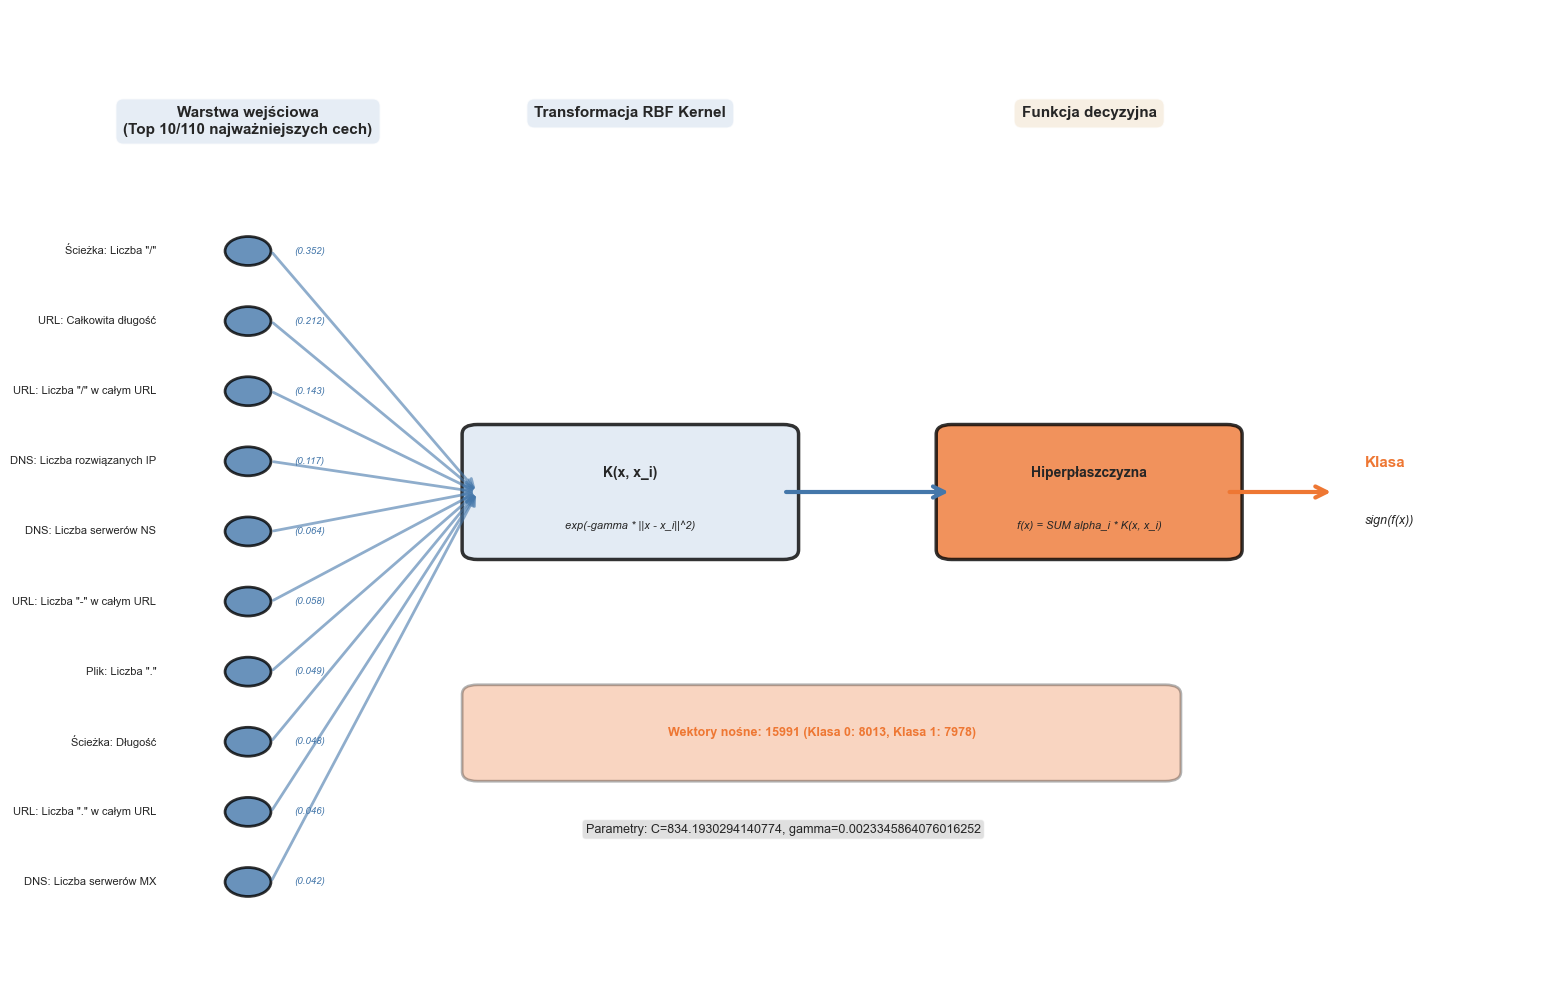

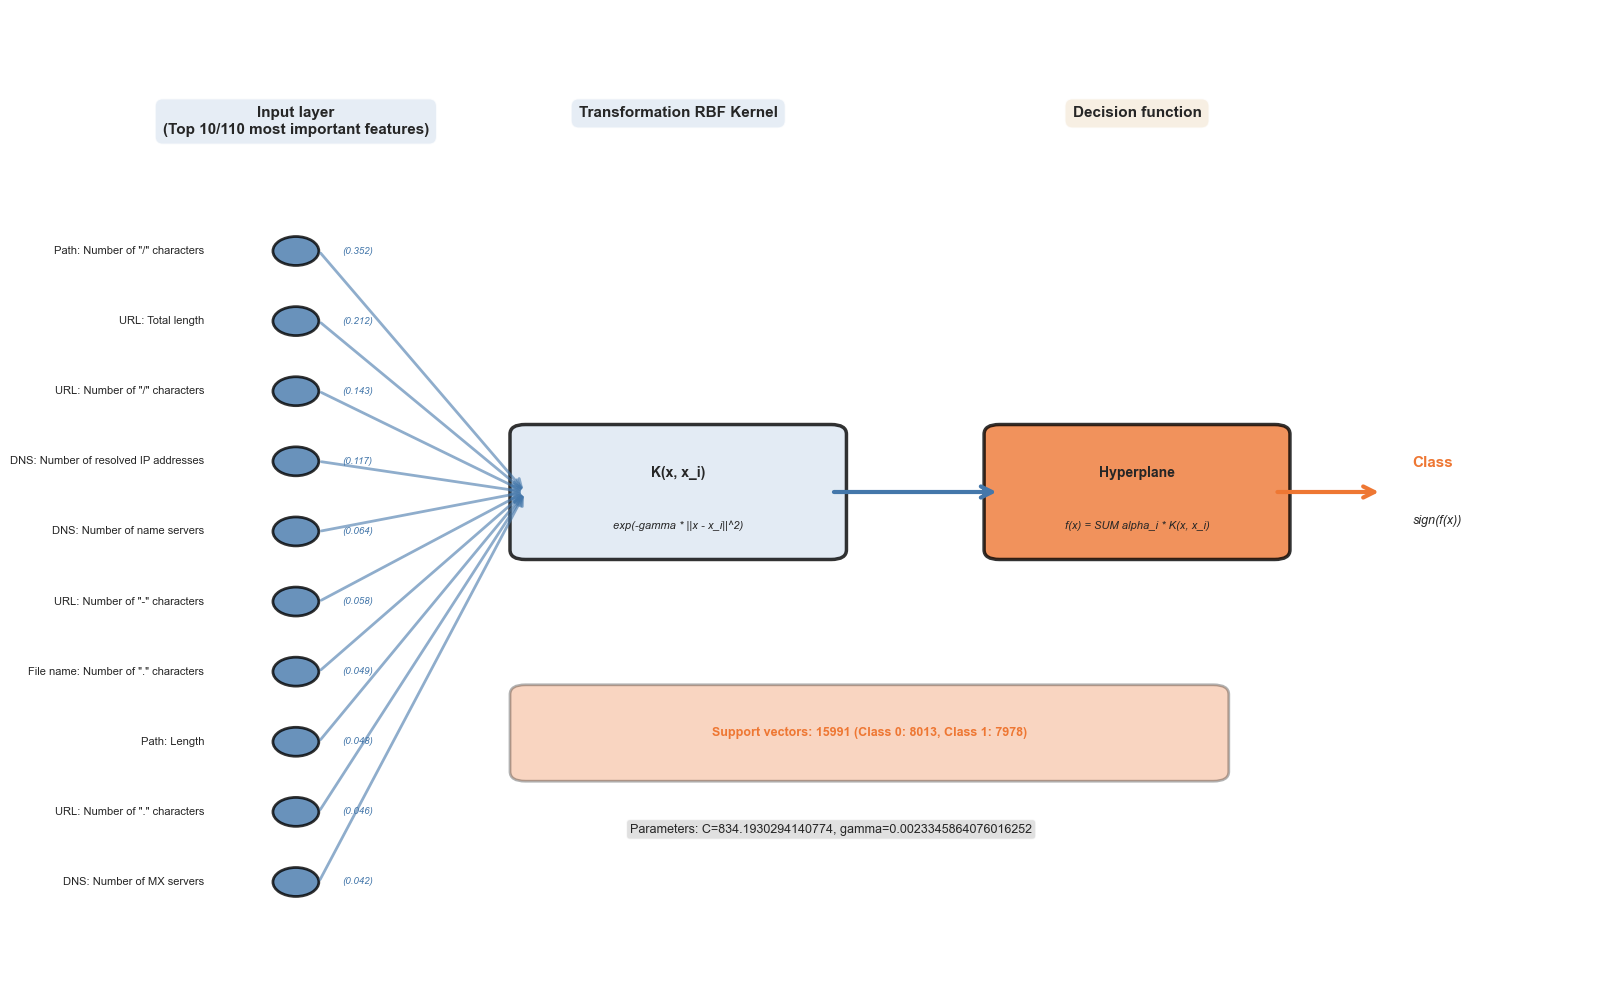

Obliczanie permutation importance dla architektury Zoptymalizowany zbiór...


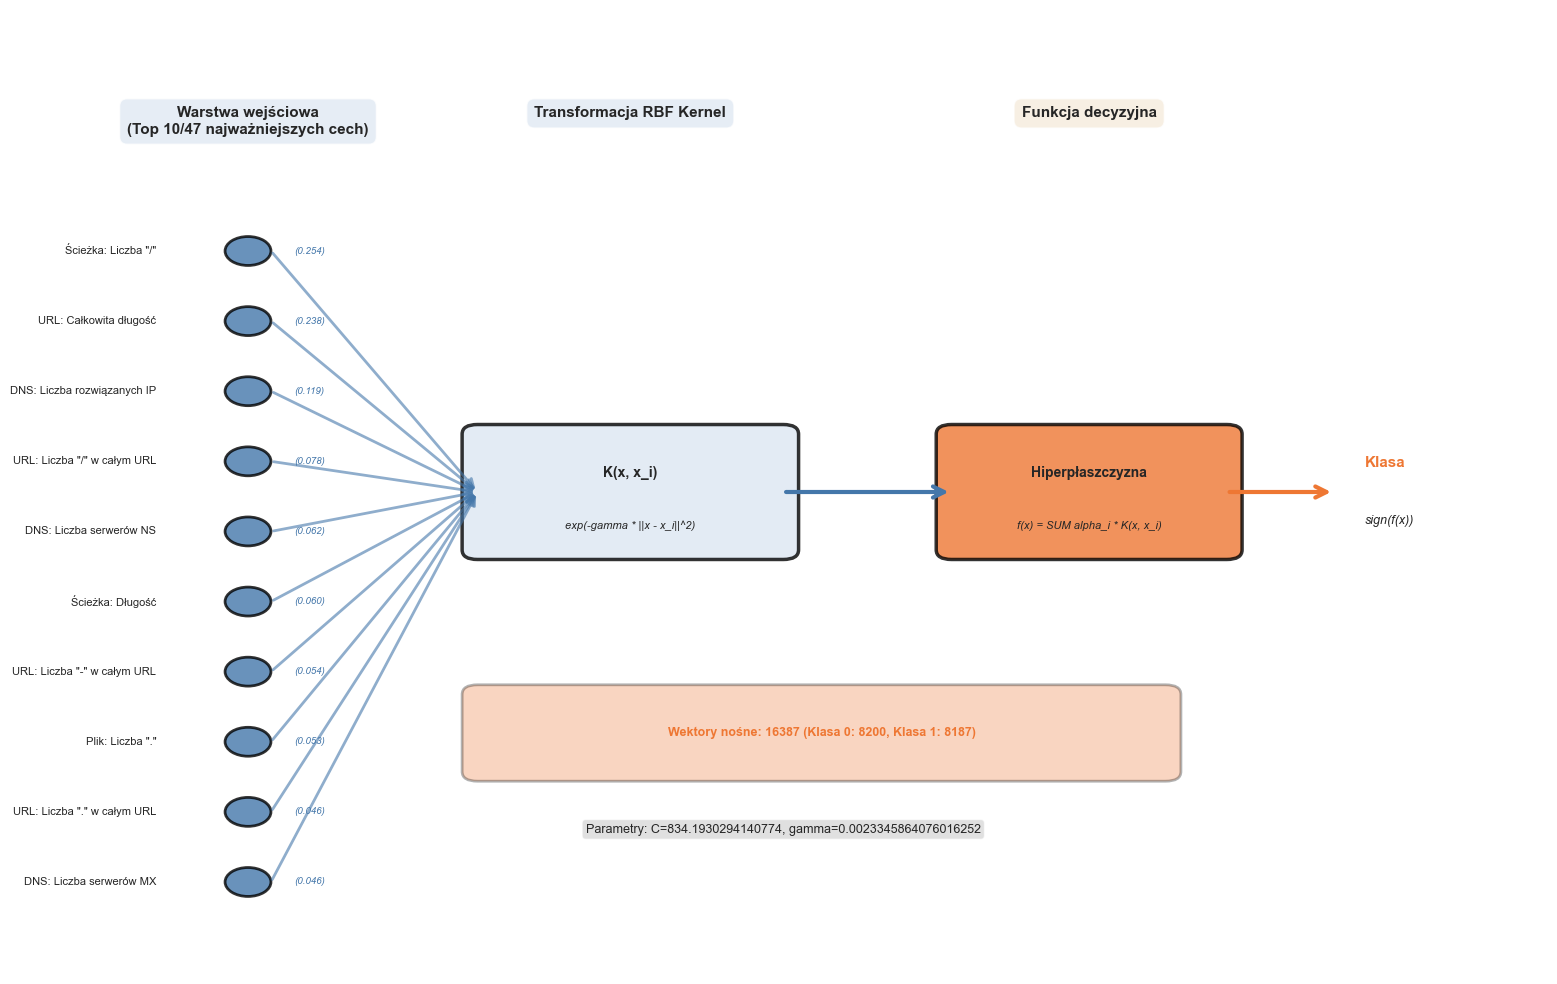

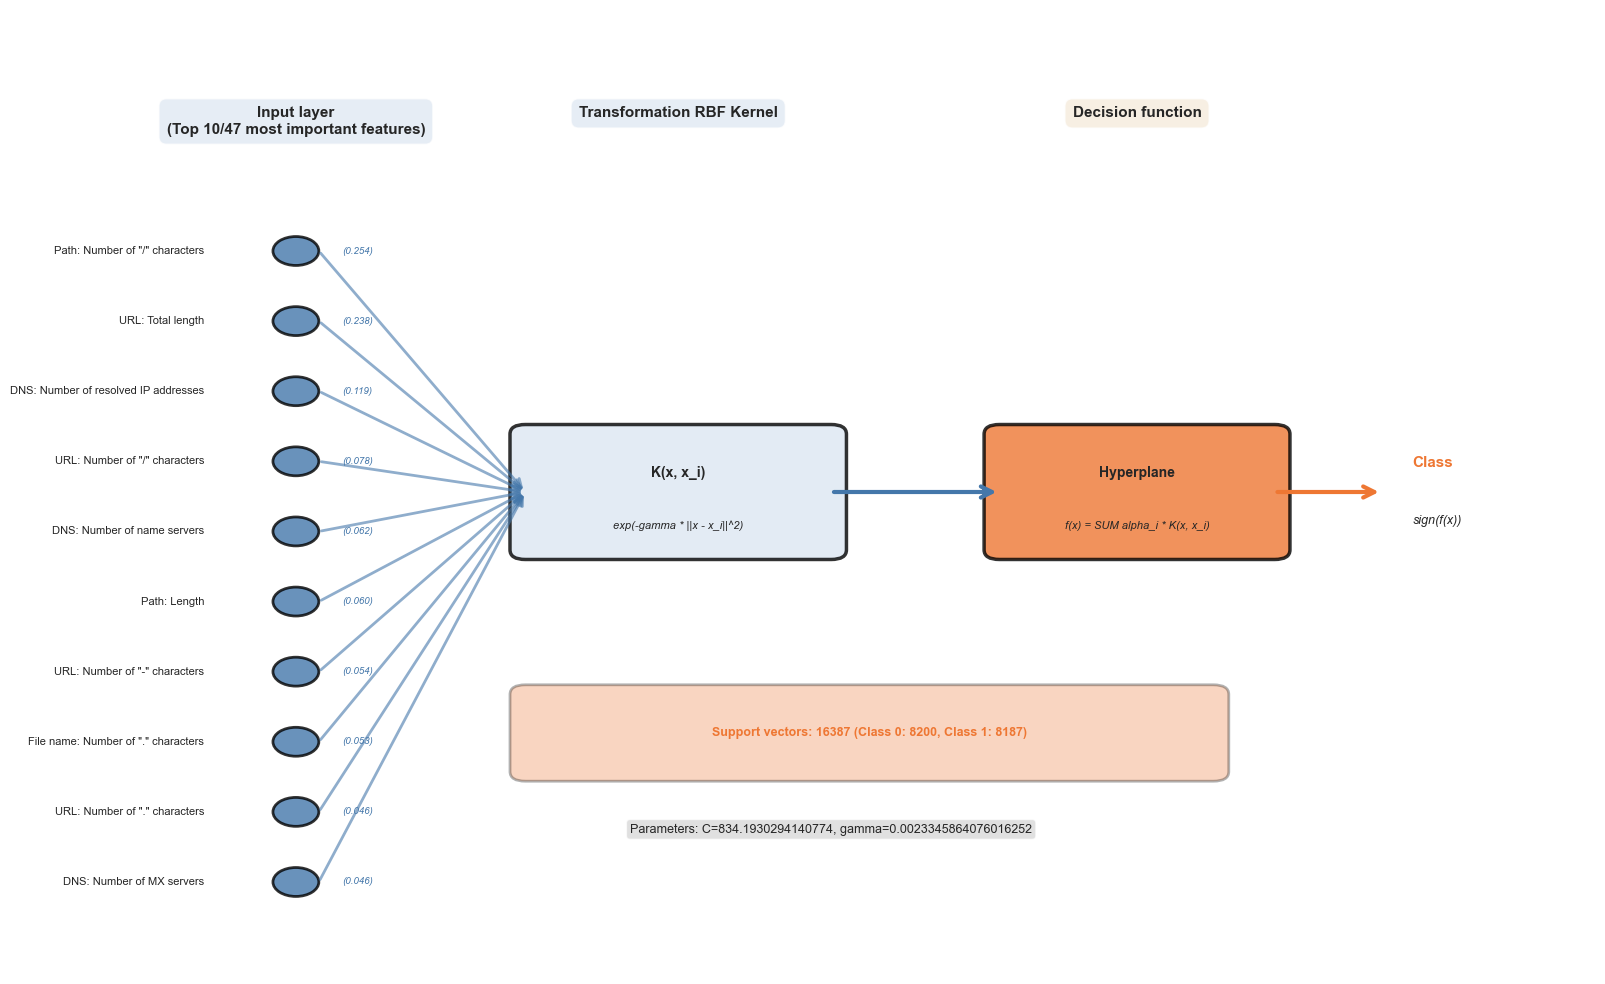

✅ Wizualizacja architektury SVM zapisana


In [13]:
dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display = [dataset_display_name(name, data_splits[name]['feature_count']) for name in data_splits]

for idx, dataset_name in enumerate(dataset_names):
    model = results_for_datasets[dataset_name]['model']
    X_train = data_splits[dataset_name]['X']
    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']
    total_features = len(X_train.columns)

    if hasattr(model, 'kernel') and model.kernel == 'linear':
        feature_importance_values = np.abs(model.coef_[0])
        kernel_display = 'Linear Kernel'
        kernel_formula = 'K(x, x_i) = x^T * x_i'
    else:
        print(f"Obliczanie permutation importance dla architektury {dataset_name}...")

        if len(X_train_scaled) > 5000:
            from sklearn.model_selection import train_test_split
            X_sample, _, y_sample, _ = train_test_split(
                X_train_scaled, y_train,
                train_size=5000,
                random_state=42,
                stratify=y_train
            )
        else:
            X_sample, y_sample = X_train_scaled, y_train

        from sklearn.inspection import permutation_importance
        perm_importance = permutation_importance(
            model, X_sample, y_sample,
            n_repeats=3,
            random_state=42,
            scoring='roc_auc',
            n_jobs=-1
        )

        feature_importance_values = perm_importance.importances_mean
        kernel_display = 'RBF Kernel'
        kernel_formula = 'exp(-gamma * ||x - x_i||^2)'

    feature_importance_df = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in X_train.columns],
        'Ważność': feature_importance_values
    }).sort_values('Ważność', ascending=False)

    top_n = 10
    top_features = feature_importance_df.head(top_n)

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    input_layer_x = 1.5
    input_spacing = 8 / (top_n + 1)


    ax.text(input_layer_x, 9, f'Warstwa wejściowa\n(Top {top_n}/{total_features} najważniejszych cech)',
            ha='center', va='top', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#DCE6F2', alpha=0.7))

    input_nodes = []
    for i, (_, row) in enumerate(top_features.iterrows()):
        y_pos = 7.5 - i * input_spacing
        color = '#4477AA'

        circle = Circle((input_layer_x, y_pos), 0.15,
                       facecolor=color, edgecolor='black', linewidth=2, alpha=0.8)
        ax.add_patch(circle)
        input_nodes.append((input_layer_x, y_pos))

        feature_text = f"{row['Cecha']}"
        ax.text(input_layer_x - 0.6, y_pos, feature_text,
               ha='right', va='center', fontsize=8)

        ax.text(input_layer_x + 0.3, y_pos, f"({row['Ważność']:.3f})",
               ha='left', va='center', fontsize=7, style='italic', color='#4477AA')

    kernel_x = 4
    kernel_y = 5

    ax.text(kernel_x, 9, f'Transformacja {kernel_display}', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='#DCE6F2', alpha=0.7))

    kernel_box = FancyBboxPatch((kernel_x - 1.0, kernel_y - 0.6), 2.0, 1.2,
                               boxstyle="round,pad=0.1",
                               facecolor='#DCE6F2', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(kernel_box)

    ax.text(kernel_x, kernel_y + 0.2, 'K(x, x_i)', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(kernel_x, kernel_y - 0.3, kernel_formula,
           ha='center', va='top', fontsize=8, style='italic')

    for inp_x, inp_y in input_nodes:
        arrow = FancyArrowPatch((inp_x + 0.15, inp_y), (kernel_x - 1.0, kernel_y),
                               arrowstyle='->', mutation_scale=15,
                               color='#4477AA', linewidth=2, alpha=0.6)
        ax.add_patch(arrow)

    decision_x = 7
    decision_y = 5

    ax.text(decision_x, 9, 'Funkcja decyzyjna', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='#F5E9D8', alpha=0.7))

    decision_box = FancyBboxPatch((decision_x - 0.9, decision_y - 0.6), 1.8, 1.2,
                                 boxstyle="round,pad=0.1",
                                 facecolor='#EE7733', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(decision_box)

    ax.text(decision_x, decision_y + 0.2, 'Hiperpłaszczyzna', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(decision_x, decision_y - 0.3, 'f(x) = SUM alpha_i * K(x, x_i)',
           ha='center', va='top', fontsize=8, style='italic')

    arrow = FancyArrowPatch((kernel_x + 1.0, kernel_y), (decision_x - 0.9, decision_y),
                           arrowstyle='->', mutation_scale=20,
                           color='#4477AA', linewidth=3)
    ax.add_patch(arrow)

    output_y = 5
    output_x = decision_x + 1.2

    ax.text(output_x + 0.6, output_y + 0.3, 'Klasa', ha='left', va='center',
           fontsize=11, fontweight='bold', color='#EE7733')
    ax.text(output_x + 0.6, output_y - 0.3, 'sign(f(x))', ha='left', va='center',
           fontsize=9, style='italic')

    arrow = FancyArrowPatch((decision_x + 0.9, decision_y), (output_x + 0.4, output_y),
                           arrowstyle='->', mutation_scale=20,
                           color='#EE7733', linewidth=3)
    ax.add_patch(arrow)

    support_vector_y = 2.5
    sv_box = FancyBboxPatch((3, support_vector_y - 0.4), 4.5, 0.8,
                           boxstyle="round,pad=0.1",
                           facecolor='#EE7733', edgecolor='black', linewidth=2, alpha=0.3)
    ax.add_patch(sv_box)

    n_support = model.n_support_
    total_sv = sum(n_support)
    ax.text(5.25, support_vector_y, f'Wektory nośne: {total_sv} (Klasa 0: {n_support[0]}, Klasa 1: {n_support[1]})',
           ha='center', va='center', fontsize=9, fontweight='bold', color='#EE7733')

    if hasattr(model, 'C') and hasattr(model, 'gamma'):
        param_info = f'Parametry: C={model.C}, gamma={model.gamma}'
    else:
        param_info = 'Parametry modelu niedostępne'

    ax.text(5, 1.5, param_info, ha='center', va='center',
           fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgray', alpha=0.7))

    plt.tight_layout()
    save_dataset_figure(fig, PLOTS_DIR, dataset_name, 'svm_architecture.png')
    plt.show()

print("✅ Wizualizacja architektury SVM zapisana")

## 7.2. Krzywe uczenia w pięciokrotnej walidacji krzyżowej

Oś pozioma przedstawia dziesięć rosnących rozmiarów podzbioru uczącego: od
10% do 100% danych dostępnych do uczenia w danym podziale. Dla każdego rozmiaru
model jest dopasowywany w pięciu podziałach. Każdy punkt linii uczenia jest
średnią miary obliczonej na pięciu podzbiorach uczących, a każdy punkt linii
walidacji jest średnią miary obliczonej na pięciu odpowiadających im
podzbiorach walidacyjnych. Pasmo oznacza ± jedno odchylenie standardowe.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.

Walidacja służy do oceny uogólniania modelu podczas jego opracowywania.
Nie jest testem końcowym. Niezależny zbiór testowy nie uczestniczy w
wyznaczaniu tych krzywych; porównanie końcowych wyników uczenia i testowania
znajduje się w sekcji ewaluacji modelu.


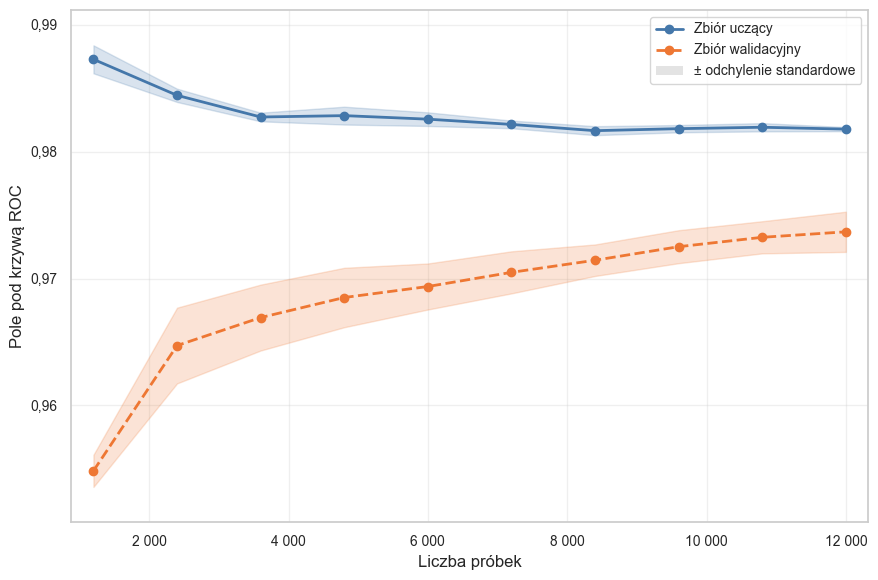

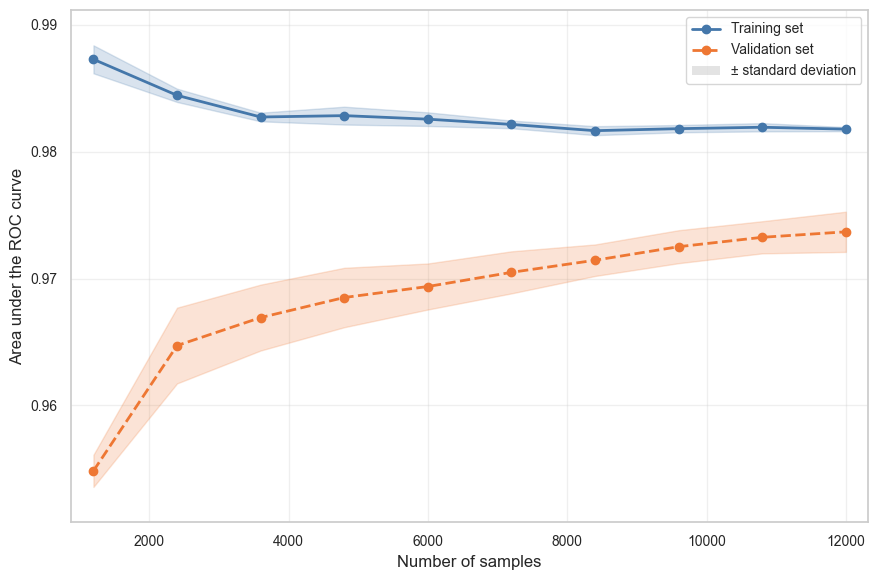

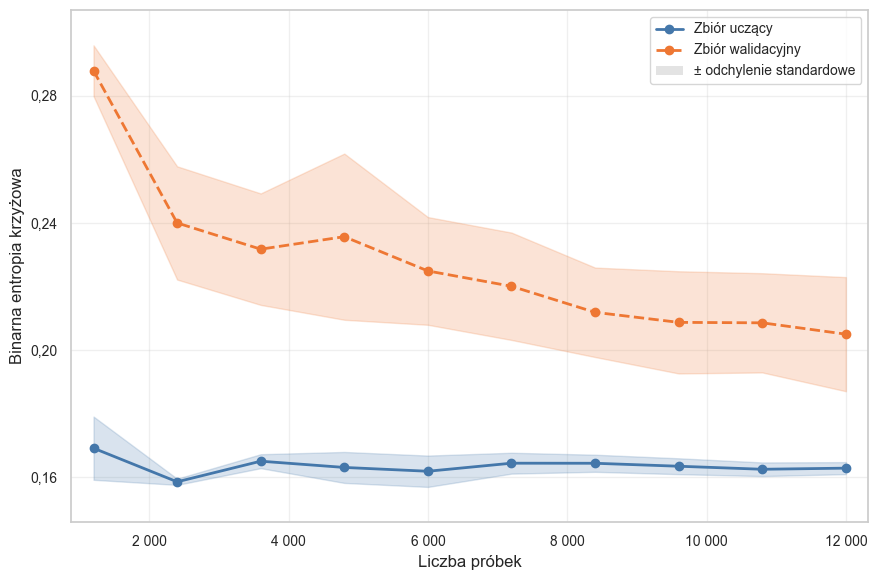

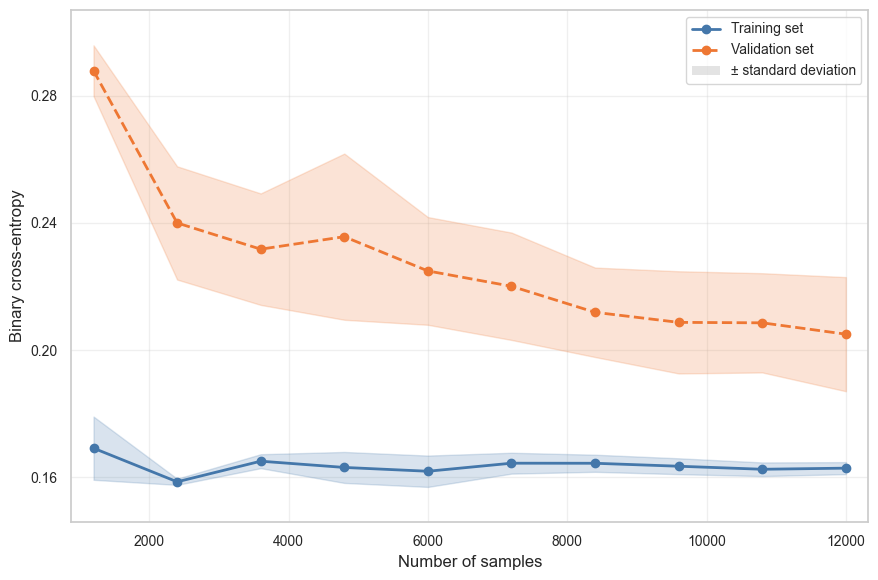

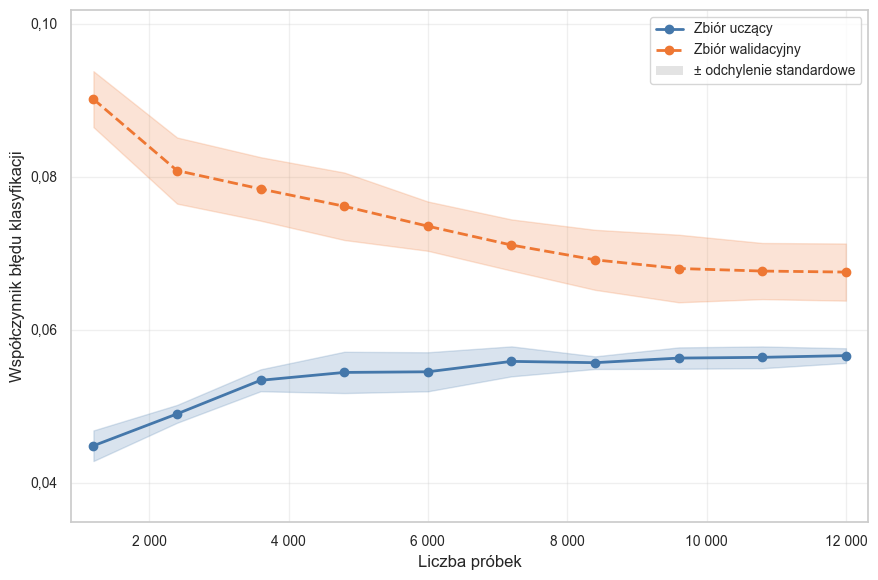

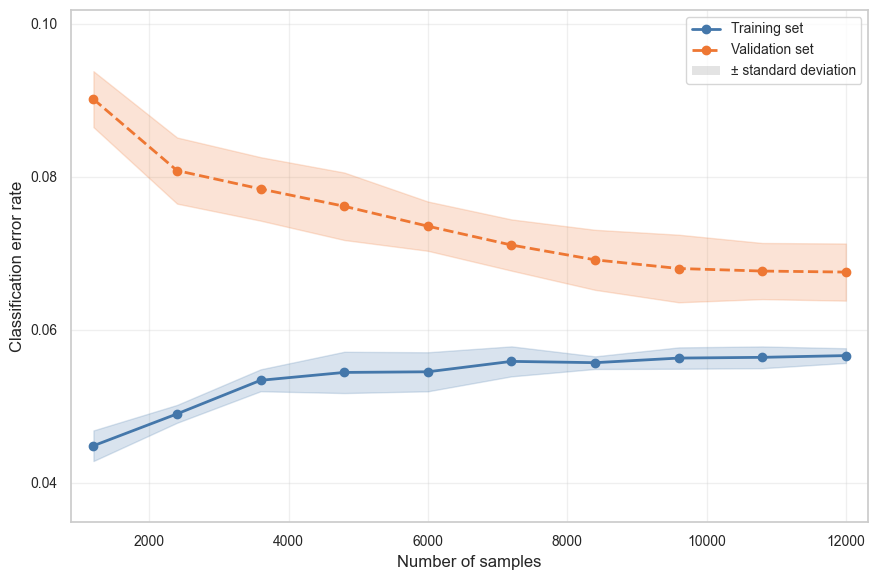

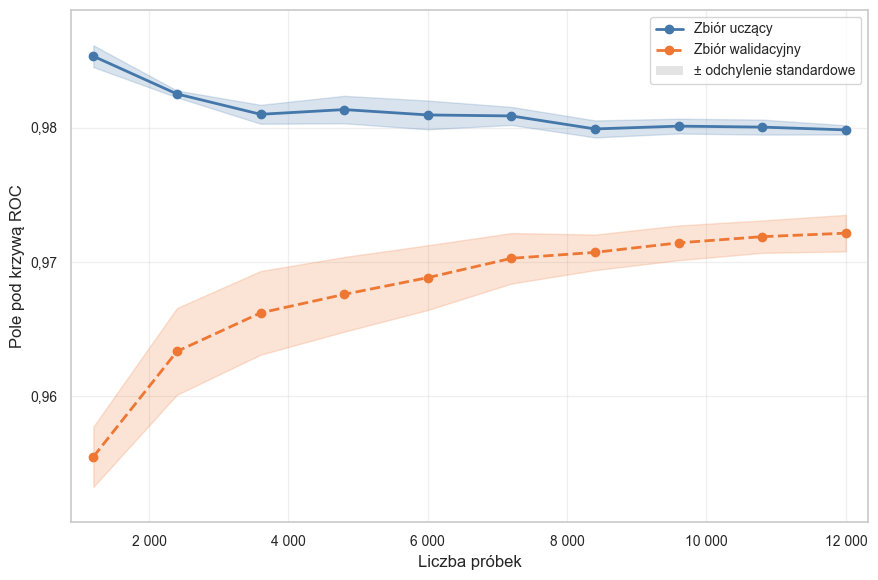

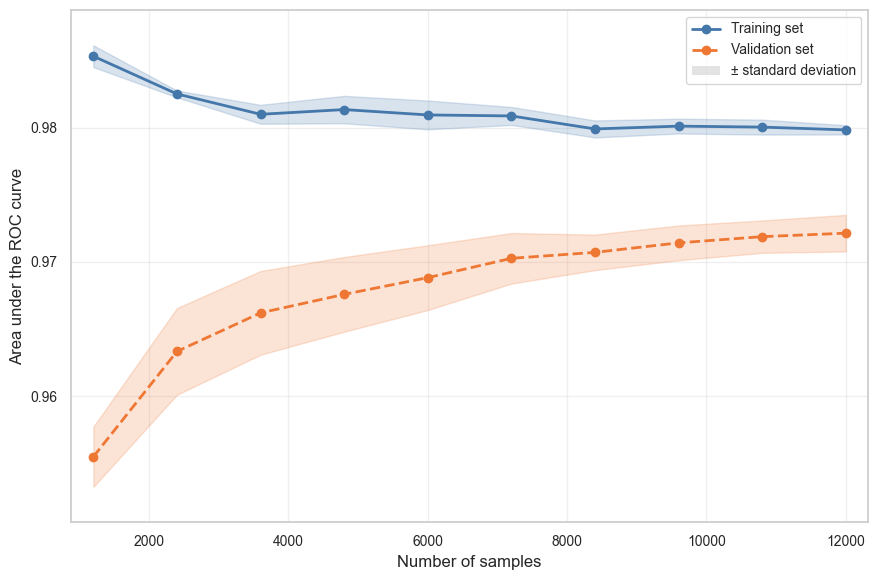

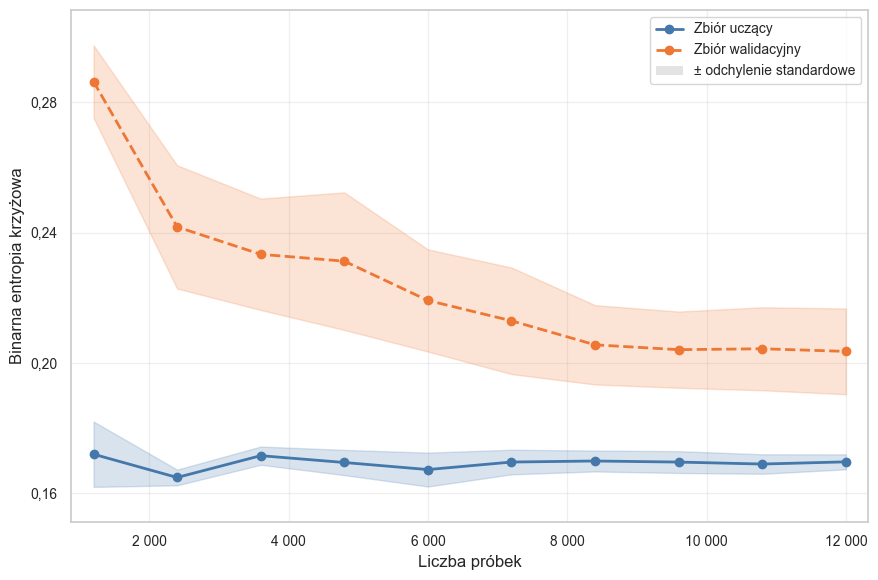

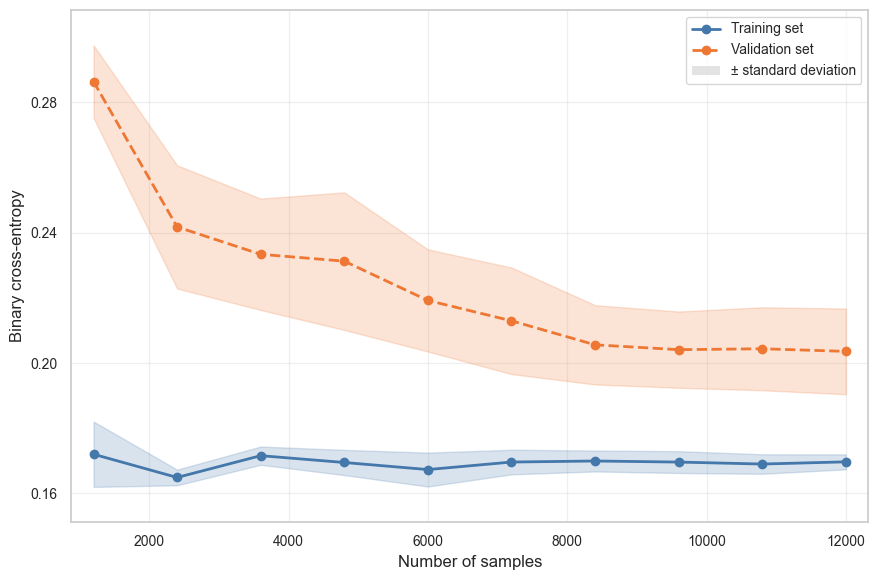

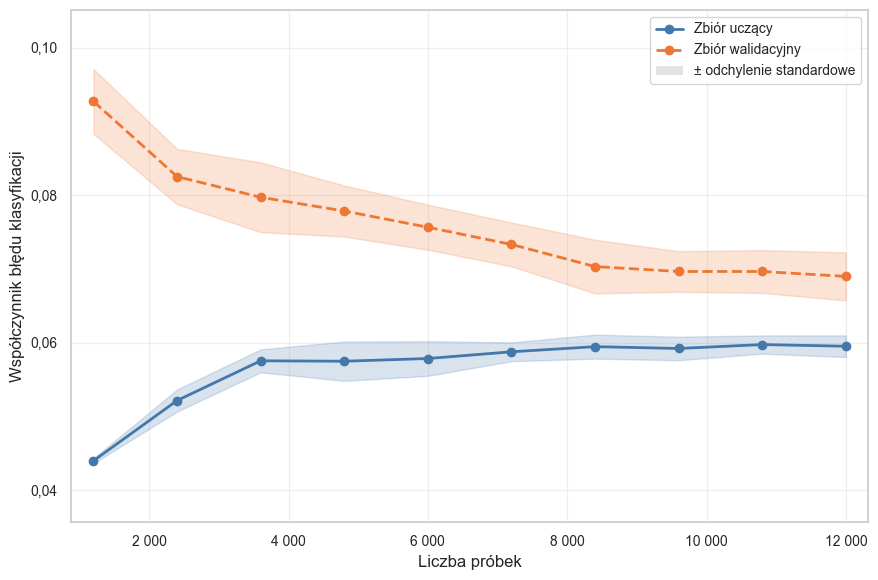

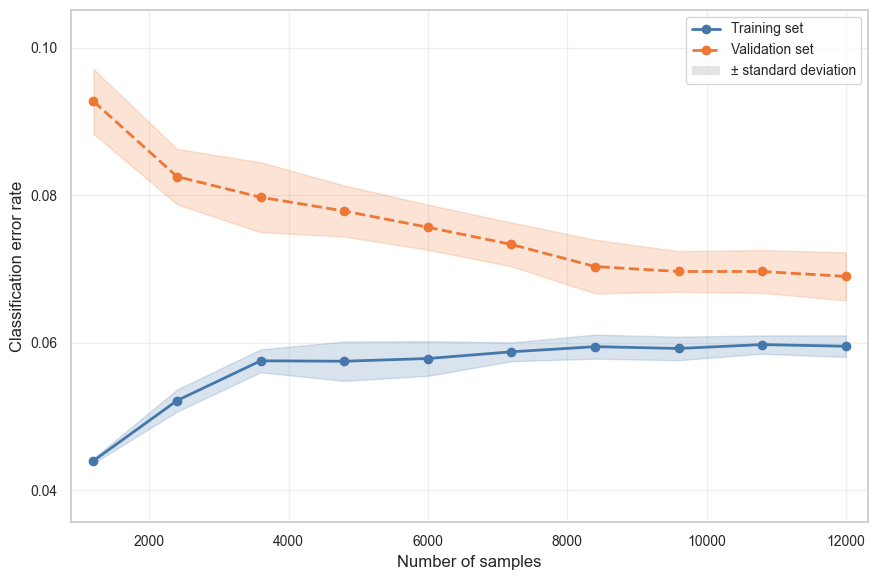

In [14]:
learning_results = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = results_for_datasets[dataset_name]['model']
    X_curve = data_splits[dataset_name]['X_train_scaled']
    y_curve = data_splits[dataset_name]['y_train']

    if len(X_curve) > 15000:
        X_curve, _, y_curve, _ = train_test_split(
            X_curve, y_curve, train_size=15000, random_state=42, stratify=y_curve
        )
    train_sizes, train_scores, validation_scores = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='roc_auc', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_log_loss, validation_log_loss = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='neg_log_loss', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_accuracy, validation_accuracy = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='accuracy', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    learning_results[dataset_name] = {
        'x': train_sizes,
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_log_loss_mean': (-train_log_loss).mean(axis=1),
        'train_log_loss_std': (-train_log_loss).std(axis=1),
        'validation_log_loss_mean': (-validation_log_loss).mean(axis=1),
        'validation_log_loss_std': (-validation_log_loss).std(axis=1),
        'train_error_rate_mean': (1.0 - train_accuracy).mean(axis=1),
        'train_error_rate_std': train_accuracy.std(axis=1),
        'validation_error_rate_mean': (1.0 - validation_accuracy).mean(axis=1),
        'validation_error_rate_std': validation_accuracy.std(axis=1),
    }

for dataset_name, values in learning_results.items():
    figure, _ = plot_score_curve(
        values['x'], values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba próbek',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'svm_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_log_loss_mean'], values['train_log_loss_std'],
        values['validation_log_loss_mean'], values['validation_log_loss_std'],
        x_label='Liczba próbek',
        y_label='Binarna entropia krzyżowa',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'svm_bce_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_error_rate_mean'], values['train_error_rate_std'],
        values['validation_error_rate_mean'], values['validation_error_rate_std'],
        x_label='Liczba próbek',
        y_label='Współczynnik błędu klasyfikacji',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'svm_error_rate_learning_curves.png')
    plt.show()


## 7.3. Wpływ regularyzacji (parametr C) na skuteczność modelu


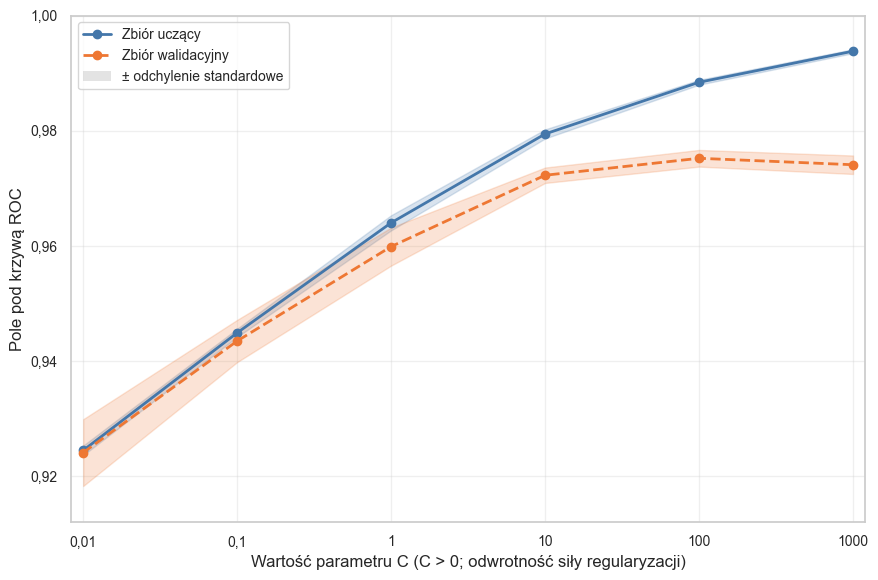

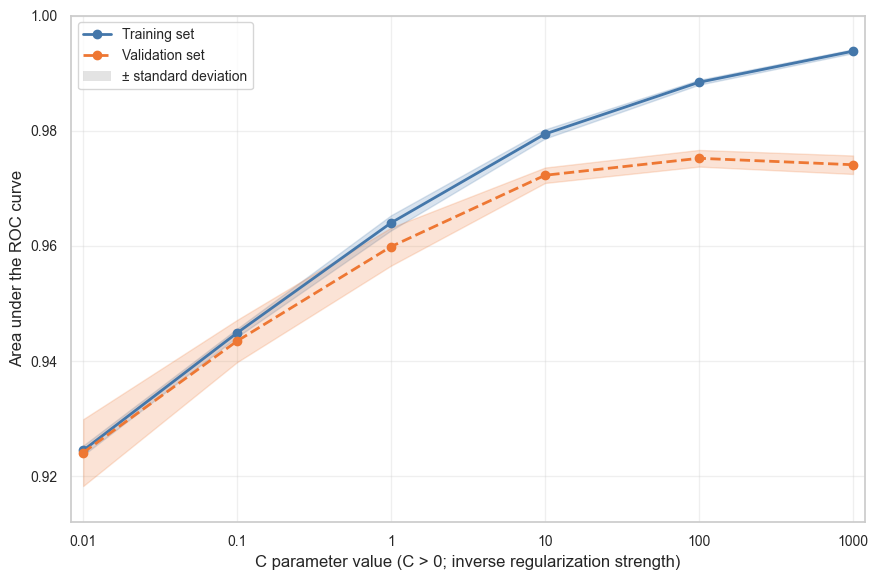

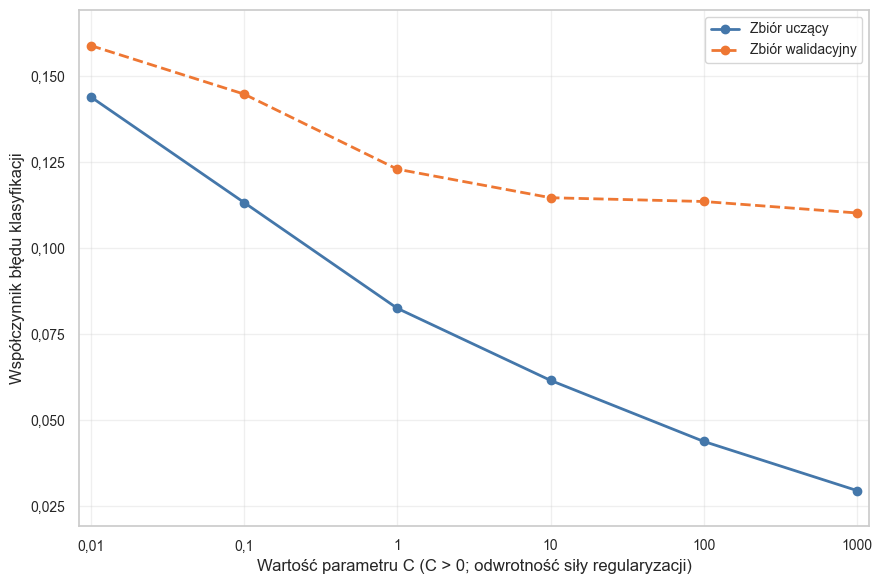

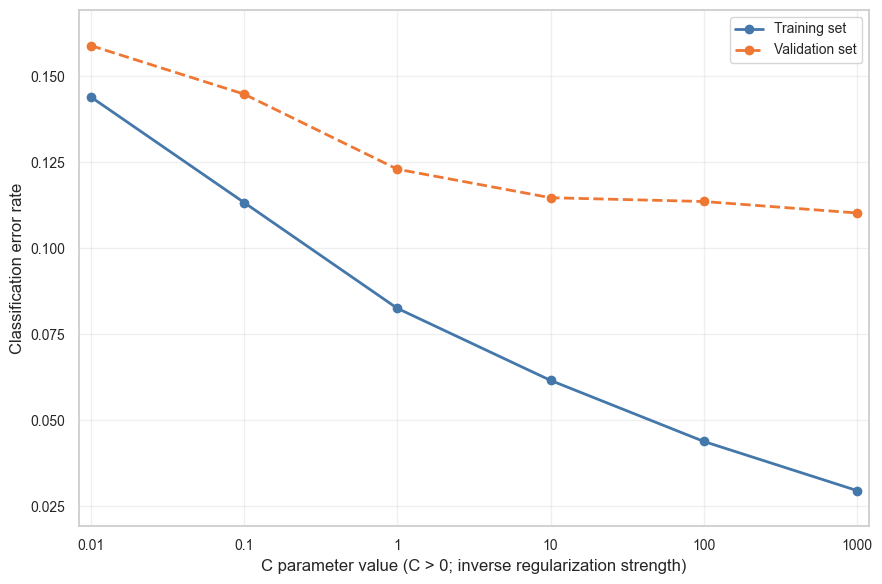

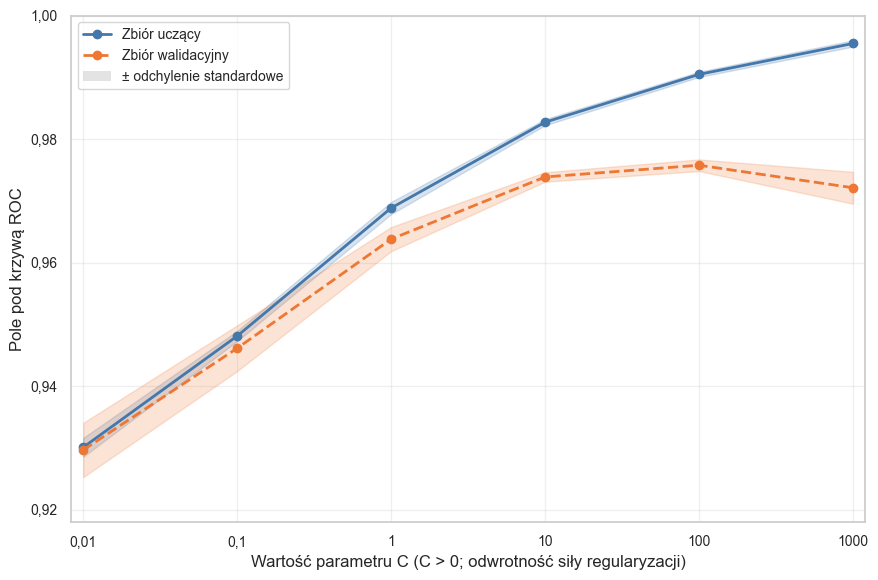

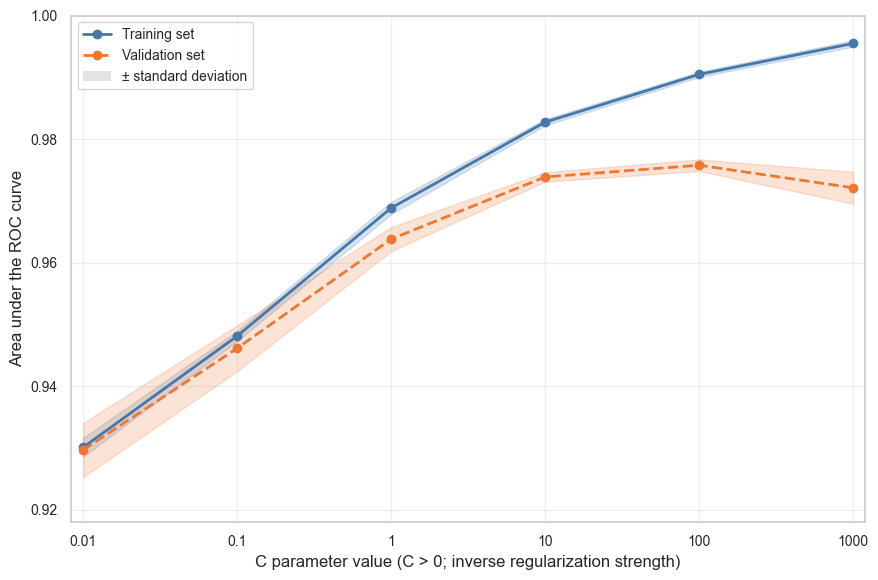

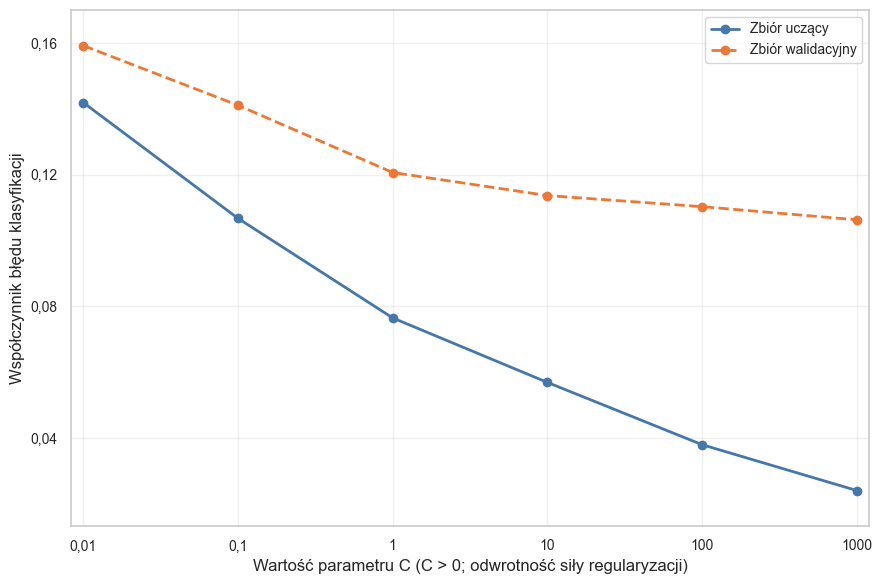

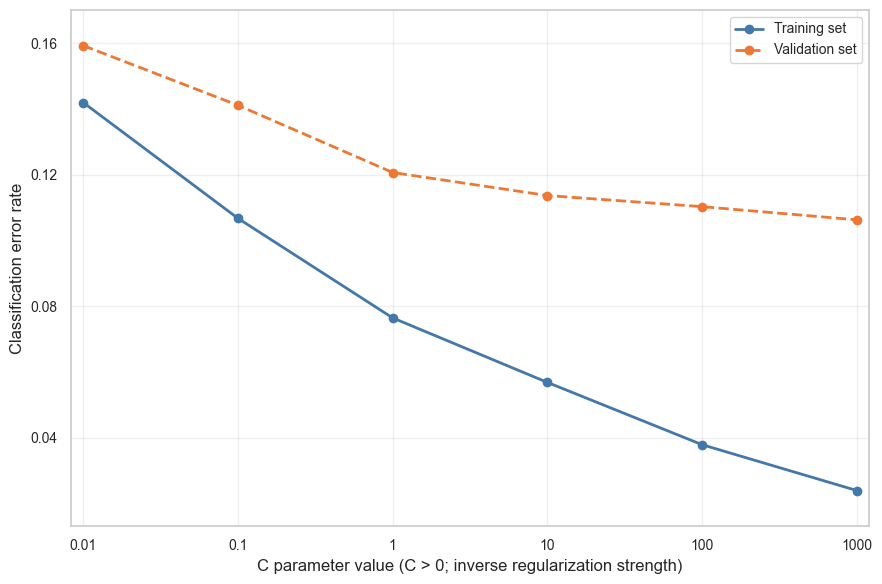

In [15]:
validation_results = {}
param_range = np.logspace(-2, 3, 6)
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    X_curve = data_splits[dataset_name]['X_train_scaled']
    y_curve = data_splits[dataset_name]['y_train']
    X_val_curve = data_splits[dataset_name]['X_test_scaled']
    y_val_curve = data_splits[dataset_name]['y_test']

    if len(X_curve) > 15000:
        X_curve, _, y_curve, _ = train_test_split(
            X_curve, y_curve, train_size=15000, random_state=42, stratify=y_curve
        )
    model_base = SVC(kernel='rbf', random_state=42, probability=True)
    train_scores, validation_scores = validation_curve(
        model_base, X_curve, y_curve, param_name='C', param_range=param_range,
        cv=3, scoring='roc_auc', n_jobs=-1,
    )
    validation_results[dataset_name] = {
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_errors': [],
        'validation_errors': [],
    }
    for parameter_value in param_range:
        parameter_model = SVC(
            C=parameter_value, kernel='rbf', random_state=42,
            probability=True,
        )
        parameter_model.fit(X_curve, y_curve)
        validation_results[dataset_name]['train_errors'].append(
            1.0 - accuracy_score(y_curve, parameter_model.predict(X_curve))
        )
        validation_results[dataset_name]['validation_errors'].append(
            1.0 - accuracy_score(y_val_curve, parameter_model.predict(X_val_curve))
        )

for dataset_name, values in validation_results.items():
    figure, _ = plot_score_curve(
        param_range, values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Wartość parametru C (C > 0; odwrotność siły regularyzacji)', logarithmic_x=True,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'svm_validation_curves.png')
    plt.show()
    figure, _ = plot_parameter_train_validation_error(
        param_range, values['train_errors'], values['validation_errors'],
        x_label='Wartość parametru C (C > 0; odwrotność siły regularyzacji)', logarithmic_x=True,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'svm_parameter_train_validation_error.png')
    plt.show()


## 7.4. Ważność cech w obu modelach


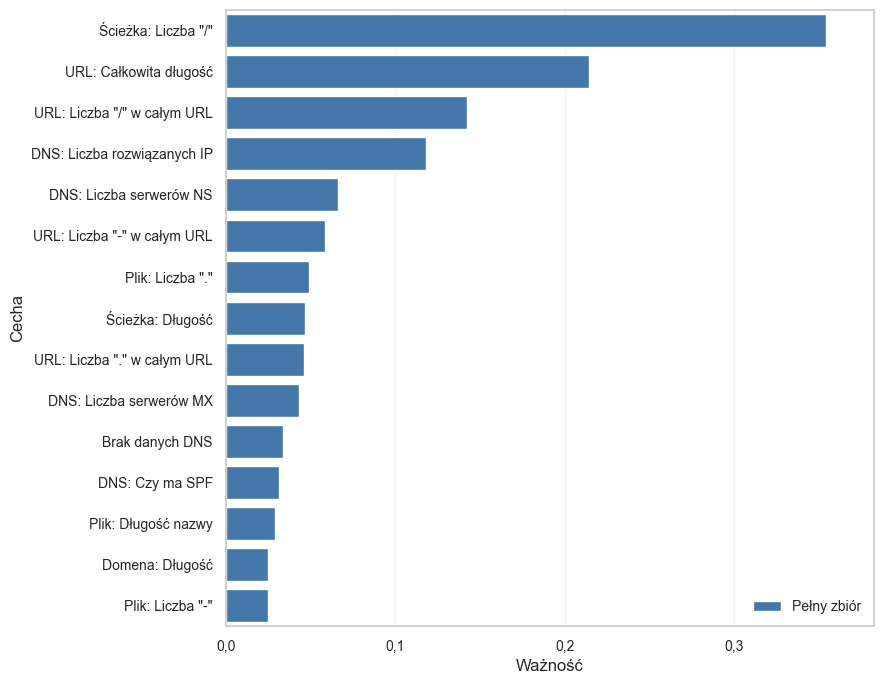

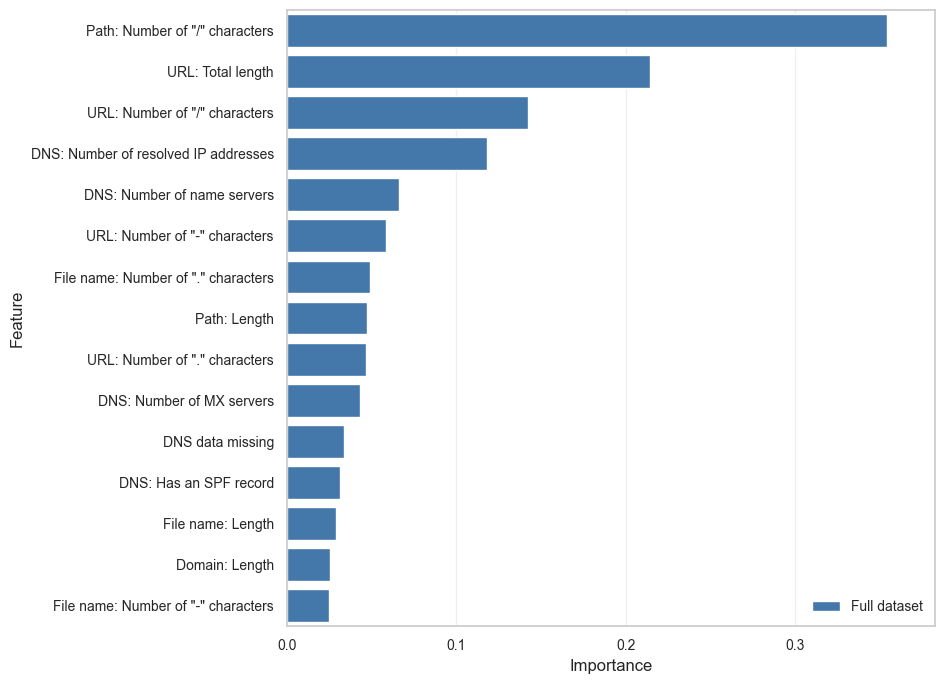

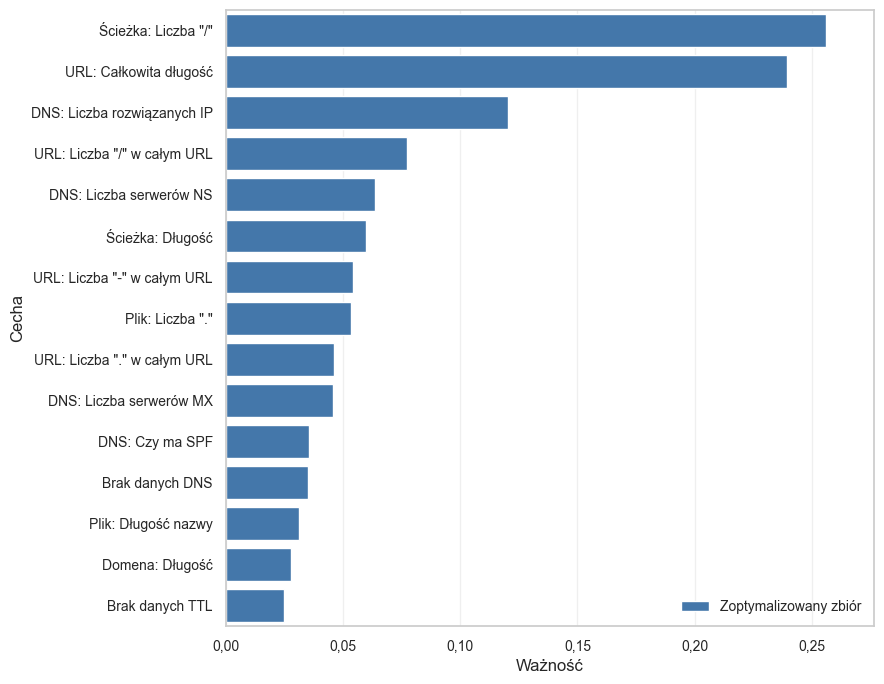

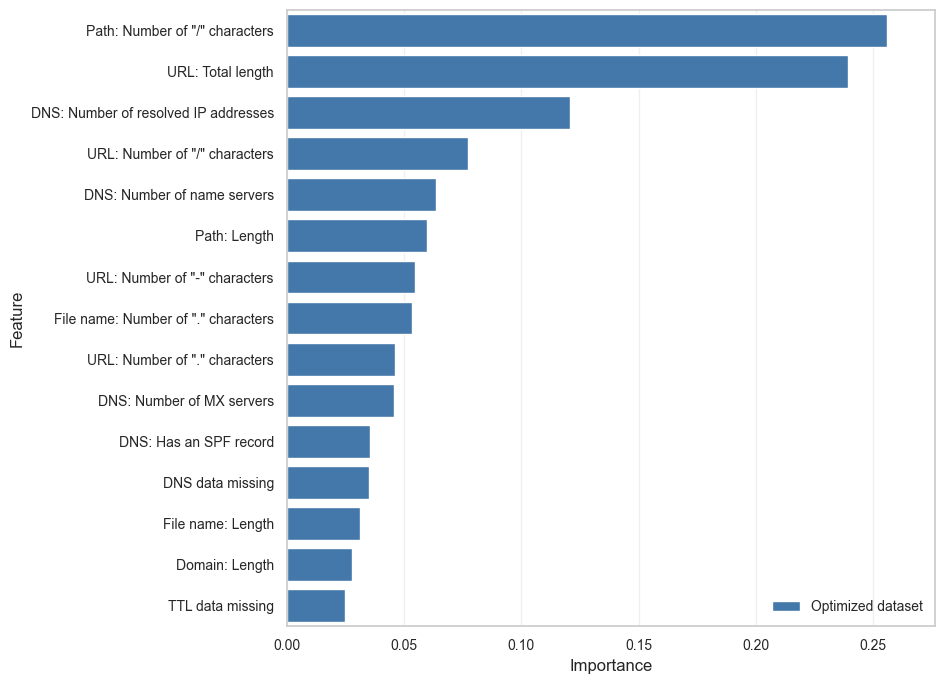

In [16]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = results_for_datasets[dataset_name]['model']
    X_features = data_splits[dataset_name]['X']
    X_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']
    if hasattr(model, 'kernel') and model.kernel == 'linear':
        importance = np.abs(model.coef_[0])
        importance_label = '|Współczynnik|'
    else:
        from sklearn.inspection import permutation_importance
        if len(X_scaled) > 5000:
            X_sample, _, y_sample, _ = train_test_split(
                X_scaled, y_train, train_size=5000, random_state=42, stratify=y_train
            )
        else:
            X_sample, y_sample = X_scaled, y_train
        importance = permutation_importance(
            model, X_sample, y_sample, n_repeats=5, random_state=42,
            scoring='roc_auc', n_jobs=-1,
        ).importances_mean
        importance_label = 'Ważność'
    ranking = pd.DataFrame({
        'Cecha': [get_readable_name(column) for column in X_features.columns],
        'Ważność': importance,
    }).sort_values('Ważność', ascending=False).head(15)
    figure, _ = plot_feature_ranking(
        ranking, dataset_name, x_column='Ważność', x_label=importance_label
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'svm_feature_importance.png')
    plt.show()


## 8. Zapis modeli


In [17]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'

    model_data = {
        'decision_threshold': evaluation_results[dataset_name]['decision_threshold'],
        'threshold_calibration': evaluation_results[dataset_name]['threshold_calibration'],
        'model': results_for_datasets[dataset_name]['model'],
        'scaler': data_splits[dataset_name]['scaler'],
        'feature_names': data_splits[dataset_name]['X'].columns.tolist(),
        'best_params': results_for_datasets[dataset_name]['best_params'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_auc_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_auc_std': evaluation_results[dataset_name]['cv_std']
        }
    }

    model_path = f'{MODELS_DIR}/svm_model_{file_suffix}_url_corpus.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model_data, f)
    print(f"✓ Model zapisany: {model_path}")

    scaler_path = f'{MODELS_DIR}/svm_scaler_{file_suffix}_url_corpus.pkl'
    with open(scaler_path, 'wb') as f:
        pickle.dump(data_splits[dataset_name]['scaler'], f)
    print(f"✓ Scaler zapisany: {scaler_path}")

comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results[name]['accuracy'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Precyzja': [evaluation_results[name]['precision'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Czułość': [evaluation_results[name]['recall'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'FPR (odsetek fałszywie dodatnich)': [evaluation_results[name]['false_positive_rate'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próg decyzyjny': [evaluation_results[name]['decision_threshold'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Miara F1': [evaluation_results[name]['f1'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'AUC-ROC': [evaluation_results[name]['auc_roc'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średnia CV AUC': [evaluation_results[name]['cv_mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Odchylenie CV AUC': [evaluation_results[name]['cv_std'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Czas uczenia (s)': [results_for_datasets[name]['training_time'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Liczba cech': [data_splits[name]['feature_count'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średnie CPU [%]': [results_with_monitoring[name]['resource_stats']['cpu']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalne CPU [%]': [results_with_monitoring[name]['resource_stats']['cpu']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średni RAM [GB]': [results_with_monitoring[name]['resource_stats']['ram']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalny RAM [GB]': [results_with_monitoring[name]['resource_stats']['ram']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próbki pomiarowe': [results_with_monitoring[name]['resource_stats']['samples'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']]
})
comparison_path = backend_root.parent / 'results' / 'url_corpus' / 'model_comparisons' / 'svm_comparison.csv'
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)
print(f"✓ Porównanie zapisane: {comparison_path}")

print(f"\n{'='*80}")
print("PODSUMOWANIE KOŃCOWE")
print(f"{'='*80}")

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{dataset_name.upper()}:")
    print(f"  Liczba cech: {len(data_splits[dataset_name]['X'].columns)}")
    print(f"  Dokładność: {evaluation_results[dataset_name]['accuracy']:.4f}")
    print(f"  F1-Score: {evaluation_results[dataset_name]['f1']:.4f}")
    print(f"  AUC-ROC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print(f"  Czas trenowania: {results_for_datasets[dataset_name]['training_time']:.2f}s")

print(f"\n✅ Wszystkie modele i wizualizacje zostały zapisane!")
print(f"Wizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")


✓ Model zapisany: ../models/svm/svm_model_full_url_corpus.pkl
✓ Scaler zapisany: ../models/svm/svm_scaler_full_url_corpus.pkl
✓ Model zapisany: ../models/svm/svm_model_optimized_url_corpus.pkl
✓ Scaler zapisany: ../models/svm/svm_scaler_optimized_url_corpus.pkl
✓ Porównanie zapisane: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/model_comparisons/svm_comparison.csv

PODSUMOWANIE KOŃCOWE

PEŁNY ZBIÓR:
  Liczba cech: 110
  Dokładność: 0.8882
  F1-Score: 0.8772
  AUC-ROC: 0.9642
  Czas trenowania: 6099.03s

ZOPTYMALIZOWANY ZBIÓR:
  Liczba cech: 47
  Dokładność: 0.8864
  F1-Score: 0.8751
  AUC-ROC: 0.9532
  Czas trenowania: 3056.61s

✅ Wszystkie modele i wizualizacje zostały zapisane!
Wizualizacje zapisane w: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/svm/
Modele zapisane w: ../models/svm/
